# KO6_Classical_Basal_LDA

## Overview

**KO6-CB** applies three AM-derived feature representations (Binary, AM-Max, Pathogenic Binary)
to the 9 literature-selected KoCoFX-CB pathways, then runs a **subagging-ensemble LDA**
to compare feature strategies for **Classical vs Basal-like** PDAC subtyping.

The PDAC cohort is bootstrapped (with replacement) N_DRAWS times; within each draw a
5-fold stratified CV produces out-of-fold scores. Fixed CV folds (computed once on the
full cohort structure) are reused across all draws — identical logic to KO6.

A second experiment extends the classification to **three classes** (Classical / Basal-like / Unknown-subtype).

**No data leakage:** `StandardScaler` is fitted on training folds only.

---

## The 9 KoCoFX-CB Pathways

| Pathway | Literature evidence | Direction |
|---------|--------------------|-----------|
| HALLMARK_KRAS Signaling Up | KRAS allelic imbalance enriched in Basal | → Basal-like |
| REACTOME_Formation of the cornified envelope | ΔNp63/cornification; Basal hallmark | → Basal-like |
| HALLMARK_Fatty Acid Metabolism | FAO upregulated in Basal (weak) | → Basal-like |
| REACTOME_Innate Immune System | Immunogenic Classical subtype | → Classical |
| REACTOME_Generic Transcription Pathway | GATA6/HNF TF network | → Classical |
| REACTOME_RNA Polymerase II Transcription | GATA6/HNF TF network | → Classical |
| REACTOME_Nervous system development | ADEX neural network | → Classical |
| HALLMARK_Apical Junction | EMT / epithelial junction loss | → Basal-like |
| REACTOME_Transport of Mature mRNA (intron-containing) | mRNA export altered in Basal | → Basal-like |

---

## Pipeline

| Cell | Section |
|------|---------|
| 0 | Setup — imports, constants, paths, helper functions |
| 1 | PDAC Metadata — CB + Unknown labels, hypermutator exclusion |
| 2 | Pathway Gene Sets — Hallmark + Reactome L2–L4 |
| 3 | Feature Matrices — 3 feature types for CvB and 3-class cohorts |
| 4 | Bootstrap & Fixed Folds (CvB) |
| 5 | Exp 1 — Binary (CvB): bootstrap-CV |
| 6 | Exp 1 — Binary (CvB): apparent |
| 7 | Exp 2 — AM Max (CvB): bootstrap-CV |
| 8 | Exp 2 — AM Max (CvB): apparent |
| 9 | Exp 3 — Pathogenic Binary (CvB): bootstrap-CV |
| 10 | Exp 3 — Pathogenic Binary (CvB): apparent |
| 11 | Comparison (CvB) — 4 figures + AUC distribution |
| 12 | Results File (CvB) |
| 13 | Bootstrap & Fixed Folds (3-class) |
| 14 | Exp 4 — Binary (3-class): bootstrap-CV + apparent |
| 15 | Exp 5 — AM Max (3-class): bootstrap-CV + apparent |
| 16 | Exp 6 — Pathogenic Binary (3-class): bootstrap-CV + apparent |
| 17 | Comparison (3-class) — 4 figures + AUC distribution |
| 18 | Results File (3-class) |

## Data

**Input**
- `merged_tcga_1000G.parquet` — TCGA-PAAD somatic mutations with `subtype` labels
  (`classical` / `basal-like` / null). Columns: `source`, `sample_id`, `gene_symbol`,
  `gene_name`, `am_pathogenicity`, `subtype`.
- Reactome hierarchy flat files + Hallmark gene sets (GSEApy) — used only to resolve the
  9 KoCoFX-CB pathway gene sets (same files as KO6_3).

**Processing**
- Exclude hypermutator (TMB > 500). CvB cohort: 142 labelled patients (81 Classical,
  61 Basal-like). 3-class cohort: 167 PDAC (+ 25 Uncertain).
- Encode three feature representations per patient over the 9 KoCoFX-CB pathways:
  Binary, AM-Max (`am_pathogenicity` max over pathway genes; 0.0 if none), and
  Pathogenic Binary (1 if any mutation with `am_pathogenicity ≥ 0.564` overlaps the pathway).
- Bootstrap N_DRAWS times (with replacement) + 5-fold stratified CV per draw → out-of-fold scores.

**Output**
- `results/CB_V*/` — per-experiment parquet / CSV files with OOF scores, AUC, F1, AUPRC
  for all six experiment × cohort combinations; comparison figures.

## Method

- **Classifier**: `LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')` (Ledoit-Wolf
  regularised); `StandardScaler` fitted on the training fold only (no data leakage).
- **Subagging design**: N_DRAWS bootstrap resamples (with replacement) of the CvB / 3-class
  cohort; within each draw, 5-fold stratified CV produces out-of-fold LDA scores. Fixed CV
  folds are computed once from the full-cohort label vector (seed 42) and reused across all
  draws so draw-to-draw score differences are attributable to resampling alone.
- **Three feature representations** over the 9 KoCoFX-CB pathways:
  (1) Binary — pathway mutated (any gene); (2) AM-Max — max pathogenicity score in pathway;
  (3) Pathogenic Binary — pathway contains a likely-pathogenic mutation (AM ≥ 0.564).
- **Apparent fit**: full-data LDA (no CV) reported alongside bootstrap-CV for comparison; not
  used for performance estimation.
- **Evaluation**: mean ± std AUC, F1, AUPRC over subagging draws; representative draw selected
  by F1 closest to the mean (consistent with KO6_3).

## Content

| # | Name | Description |
|---|------|-------------|
| 0 | Setup | Imports, constants (`N_DRAWS`, `AM_THRESHOLD`, `RANDOM_SEED`), paths, colours, pathway definitions |
| 1 | PDAC Metadata | Load TCGA-PAAD; exclude hypermutator (TMB > 500); derive CvB and 3-class label vectors; fixed 5-fold CV folds |
| 2 | Pathway Gene Sets | Reactome L2–L4 + Hallmark; verify 9 KoCoFX-CB pathway names |
| 3 | Feature Matrices | Build Binary, AM-Max, Pathogenic Binary matrices for CvB and 3-class cohorts |
| 4 | Bootstrap & Fixed Folds (CvB) | N_DRAWS resamples with replacement; precompute bootstrap index arrays |
| 5 | Experiment 1 — Binary (CvB): Bootstrap-CV | OOF LDA scores over N_DRAWS bootstrap-CV runs; mean AUC / F1 / AUPRC |
| 6 | Experiment 1 — Binary (CvB): Apparent | Full-data LDA fit; ROC / PRC / confusion matrix |
| 7 | Experiment 2 — AM Max (CvB): Bootstrap-CV | Same design with AM-Max representation |
| 8 | Experiment 2 — AM Max (CvB): Apparent | Apparent full-data fit |
| 9 | Experiment 3 — Pathogenic Binary (CvB): Bootstrap-CV | Same design with Pathogenic Binary |
| 10 | Experiment 3 — Pathogenic Binary (CvB): Apparent | Apparent full-data fit |
| 11 | Comparison (CvB) — Figures | Unified metrics table + OOF vs apparent curves for all three representations |
| 12 | Results File (CvB) | Write comparison table and per-draw AUC/F1/AUPRC to `results/CB_V*/` |
| 13 | Bootstrap & Fixed Folds (3-class) | Same bootstrap design for Classical / Basal-like / Unknown (3-class LDA) |
| 14 | Experiment 4 — Binary (3-class) | Bootstrap-CV + apparent for Binary features, 3-class |
| 15 | Experiment 5 — AM Max (3-class) | Bootstrap-CV + apparent for AM-Max features, 3-class |
| 16 | Experiment 6 — Pathogenic Binary (3-class) | Bootstrap-CV + apparent for Pathogenic Binary features, 3-class |
| 17 | Comparison (3-class) — Figures | Unified metrics + curves for all three representations, 3-class task |
| 18 | Results File (3-class) | Write 3-class results to `results/CB_V*/` |

## 0. Setup

In [2]:
from collections import defaultdict, deque
import re
import warnings
from pathlib import Path

import gseapy as gp
import matplotlib.patches as mpatches
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc,
    average_precision_score, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

# ── KoCoFX-CB feature set ─────────────────────────────────────────────────────
KOCOFX_CB_PATHWAYS = [
    'HALLMARK_KRAS Signaling Up',
    'REACTOME_Formation of the cornified envelope',
    'HALLMARK_Fatty Acid Metabolism',
    'REACTOME_Innate Immune System',
    'REACTOME_Generic Transcription Pathway',
    'REACTOME_RNA Polymerase II Transcription',
    'REACTOME_Nervous system development',
    'HALLMARK_Apical Junction',
    'REACTOME_Transport of Mature mRNA derived from an Intron-Containing Transcript',
]

KOCOFX_CB_LITERATURE = {
    'HALLMARK_KRAS Signaling Up':               ('Clear signal', '-> Basal-like'),
    'REACTOME_Formation of the cornified envelope': ('Clear signal', '-> Basal-like'),
    'HALLMARK_Fatty Acid Metabolism':           ('Weak signal',  '-> Basal-like'),
    'REACTOME_Innate Immune System':            ('Clear signal', '-> Classical'),
    'REACTOME_Generic Transcription Pathway':   ('Clear signal', '-> Classical'),
    'REACTOME_RNA Polymerase II Transcription': ('Clear signal', '-> Classical'),
    'REACTOME_Nervous system development':      ('Clear signal', '-> Classical'),
    'HALLMARK_Apical Junction':                 ('Clear signal', '-> Basal-like'),
    'REACTOME_Transport of Mature mRNA derived from an Intron-Containing Transcript': ('Clear signal', '-> Basal-like'),
}

N_DRAWS        = 100
N_CV_SPLITS    = 5
RANDOM_SEED    = 42
AM_PATH_MIN    = 0.564
MAX_REACTOME_LEVEL = 3
MIN_REACTOME_LEVEL = 1

SUBTYPE_CLASSICAL = 'classical'
SUBTYPE_BASAL     = 'basal-like'

# ── Paths ─────────────────────────────────────────────────────────────────────
# DATA_DIR       = Path('C:/Users/daane/Desktop/DATA')
DATA_DIR       = Path('C:/2604_BRP/Data')
PARQUET        = DATA_DIR / 'merged_tcga_1000G.parquet'
REACTOME_DIR   = DATA_DIR / 'reactome_hierarchy'
RESULTS_DIR    = DATA_DIR / 'results'
# REPO_ROOT      = Path('C:/Users/daane/Desktop/GitHub Repos/Bachelor_Research_Project')
REPO_ROOT      = Path('C:/2604_BRP/Bachelor_Research_Project')
RESULTS_DIR_CB = RESULTS_DIR / 'AM_CvB'
RESULTS_DIR_CB.mkdir(exist_ok=True)

# ── Colours (Wong colour-blind-safe palette) ──────────────────────────────────
WONG = {
    'orange':    '#E69F00',
    'sky_blue':  '#56B4E9',
    'green':     '#009E73',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
}
YELLOW_WARM = '#E6C229'   # Classical
RED_DEEP    = '#C72C2C'   # Basal-like
GREY        = '#999999'   # Unknown (3-class)

# ── Feature-type display config ───────────────────────────────────────────────
FEAT_LABELS = ['Binary', 'AM Max', 'Pathogenic Binary']
FEAT_COLORS = [WONG['vermilion'], WONG['blue'], WONG['green']]

# ── Helper functions (identical to KO6) ──────────────────────────────────────
def build_koco_matrix(sample_ids, sample_gene_sets, pathways, pw_sets):
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for g in sample_gene_sets.get(sid, set()):
            for j in gene_to_pw.get(g, []):
                X[i, j] = 1.0
    return X

def build_koco_am_matrix(sample_ids, sample_mutations, pathways, pw_sets):
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for gene, score in sample_mutations.get(sid, []):
            for j in gene_to_pw.get(gene, []):
                if score > X[i, j]:
                    X[i, j] = score
    return X

def build_koco_pathogenic_matrix(sample_ids, sample_mutations, pathways, pw_sets,
                                  threshold=AM_PATH_MIN):
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for gene, score in sample_mutations.get(sid, []):
            if score >= threshold:
                for j in gene_to_pw.get(gene, []):
                    X[i, j] = 1.0
    return X

print(f'Results dir  : {RESULTS_DIR_CB}')
print(f'Parquet      : {PARQUET.exists()}')
print(f'Draws        : {N_DRAWS}  x  {N_CV_SPLITS}-fold CV = {N_DRAWS * N_CV_SPLITS} fits')
print(f'CB pathways  : {len(KOCOFX_CB_PATHWAYS)}')
print(f'AM threshold : {AM_PATH_MIN}')

Results dir  : C:\2604_BRP\Data\results\AM_CvB
Parquet      : True
Draws        : 100  x  5-fold CV = 500 fits
CB pathways  : 9
AM threshold : 0.564


## 1. PDAC Metadata

In [3]:
df_meta = (
    pl.read_parquet(PARQUET, columns=["source", "sample_id", "subtype"])
    .unique("sample_id")
)

tmb_df = (
    pl.read_parquet(PARQUET, columns=["source", "sample_id"])
    .filter(pl.col("source") == "TCGA")
    .group_by("sample_id").agg(pl.len().alias("tmb"))
)
hypermutator_ids = set(
    tmb_df.filter(pl.col("tmb") > 500)["sample_id"].to_list()
)

df_tcga_meta = (
    df_meta
    .filter(
        (pl.col("source") == "TCGA") &
        ~pl.col("sample_id").is_in(hypermutator_ids)
    )
    .sort("sample_id")
)

# ── CvB cohort ────────────────────────────────────────────────────────────────────────────────
df_cvb    = df_tcga_meta.filter(pl.col("subtype").is_in([SUBTYPE_CLASSICAL, SUBTYPE_BASAL]))
cvb_ids   = df_cvb["sample_id"].to_list()
y_cvb     = (df_cvb["subtype"] == SUBTYPE_BASAL).cast(pl.Int8).to_numpy()

classical_ids = [cvb_ids[i] for i in range(len(cvb_ids)) if y_cvb[i] == 0]
basal_ids     = [cvb_ids[i] for i in range(len(cvb_ids)) if y_cvb[i] == 1]
n_classical   = len(classical_ids)
n_basal       = len(basal_ids)
n_cvb         = len(cvb_ids)

# ── 3-class cohort: CvB + Unknown ────────────────────────────────────────────────────────────
# is_in returns null for null subtype values; explicitly include nulls as Unknown
df_unknown = df_tcga_meta.filter(
    pl.col("subtype").is_null() | ~pl.col("subtype").is_in([SUBTYPE_CLASSICAL, SUBTYPE_BASAL])
)
unknown_ids = df_unknown["sample_id"].to_list()
n_unknown   = len(unknown_ids)

all_3class_ids = cvb_ids + unknown_ids
y_3class       = np.concatenate([y_cvb, np.full(n_unknown, 2, dtype=np.int8)])
n_3class       = len(all_3class_ids)

print(f"Hypermutators excluded (TMB > 500): {sorted(hypermutator_ids)}")
print(f"Classical  : {n_classical}")
print(f"Basal-like : {n_basal}")
print(f"Unknown    : {n_unknown}")
print(f"CvB total  : {n_cvb}")
print(f"3-class total: {n_3class}")

Hypermutators excluded (TMB > 500): ['TCGA-IB-7651']
Classical  : 81
Basal-like : 61
Unknown    : 25
CvB total  : 142
3-class total: 167


## 2. Pathway Gene Sets (Hallmark + Reactome L2–L4)

In [4]:
pw_txt  = (REACTOME_DIR / 'ReactomePathways.txt').read_text(encoding='utf-8')
rel_txt = (REACTOME_DIR / 'ReactomePathwaysRelation.txt').read_text(encoding='utf-8')
gmt_txt = (REACTOME_DIR / 'ReactomePathways.gmt').read_text(encoding='utf-8')

human_id_to_name: dict = {}
for line in pw_txt.strip().splitlines():
    parts = line.split('\t')
    if len(parts) >= 3 and parts[2].strip() == 'Homo sapiens':
        human_id_to_name[parts[0].strip()] = parts[1].strip()
human_ids = set(human_id_to_name)

parent_to_children: dict = defaultdict(set)
child_to_parents:   dict = defaultdict(set)
for line in rel_txt.strip().splitlines():
    parts = line.strip().split('\t')
    if len(parts) < 2:
        continue
    parent, child = parts[0], parts[1]
    if parent in human_ids and child in human_ids:
        parent_to_children[parent].add(child)
        child_to_parents[child].add(parent)

all_in_dag = set(parent_to_children) | set(child_to_parents)
roots      = {pid for pid in all_in_dag if pid not in child_to_parents}
level_of: dict = {}
queue = deque()
for r in roots:
    level_of[r] = 0
    queue.append(r)
while queue:
    node = queue.popleft()
    for child in parent_to_children.get(node, set()):
        if child not in level_of:
            level_of[child] = level_of[node] + 1
            queue.append(child)

gmt_by_id:  dict = {}
name_to_id: dict = {}
for line in gmt_txt.strip().splitlines():
    parts = line.split('\t')
    if len(parts) < 3:
        continue
    name  = parts[0]
    url   = parts[1]
    genes = {g.strip() for g in parts[2:] if g.strip()}
    m = re.search(r'R-HSA-\d+', url)
    if not m:
        continue
    rid = m.group(0)
    gmt_by_id[rid]   = {'name': name, 'genes': genes}
    name_to_id[name] = rid

_raw_hallmark = gp.get_library('MSigDB_Hallmark_2020')
hallmark_sets = {k: set(v) for k, v in _raw_hallmark.items()}

reactome_selected: dict = {}
for rid, info in gmt_by_id.items():
    if MIN_REACTOME_LEVEL <= level_of.get(rid, 99) <= MAX_REACTOME_LEVEL and info['genes']:
        reactome_selected[info['name']] = info['genes']

pw_sets: dict = {}
for name, genes in hallmark_sets.items():
    pw_sets[f'HALLMARK_{name}'] = genes
for name, genes in reactome_selected.items():
    key = f'REACTOME_{name}'
    if key not in pw_sets:
        pw_sets[key] = genes

pw_names = sorted(pw_sets.keys())

def pw_level_tag(pw_name):
    if not pw_name.startswith('REACTOME_'):
        return ''
    base = pw_name[len('REACTOME_'):]
    rid  = name_to_id.get(base)
    if rid is None:
        return ''
    lv = level_of.get(rid)
    return f'(Reactome-L{lv + 1})' if lv is not None else ''

# Validate all CB pathways present
for pw in KOCOFX_CB_PATHWAYS:
    if pw not in pw_sets:
        raise KeyError(f'Pathway not found in pw_sets: {pw!r}')

for lv in range(MIN_REACTOME_LEVEL, MAX_REACTOME_LEVEL + 1):
    n = sum(1 for rid in gmt_by_id if level_of.get(rid) == lv)
    print(f'Reactome-L{lv + 1}: {n} pathways')
print(f'Total pw_sets: {len(pw_sets)}')
print('All 9 KoCoFX-CB pathways found: OK')

Reactome-L2: 188 pathways
Reactome-L3: 504 pathways
Reactome-L4: 920 pathways
Total pw_sets: 1662
All 9 KoCoFX-CB pathways found: OK


## 3. Feature Matrices (3 Feature Types)

In [5]:
# Load TCGA mutations with am_pathogenicity for all relevant patients
all_pdac_ids = list(set(cvb_ids + unknown_ids))

df_tcga_mut = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name', 'am_pathogenicity'],
    )
    .filter(
        (pl.col('source') == 'TCGA') &
        pl.col('sample_id').is_in(all_pdac_ids)
    )
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
    .unique(['sample_id', 'gene', 'am_pathogenicity'])
)

# Build lookup dicts
sample_gene_sets: dict = {}    # sid -> set of gene names (for Binary)
sample_mutations: dict = {}    # sid -> list of (gene, am_pathogenicity) (for AM/Pathogenic)

for row in (
    df_tcga_mut
    .group_by('sample_id')
    .agg(pl.col('gene'), pl.col('am_pathogenicity'))
    .iter_rows(named=True)
):
    sid   = row['sample_id']
    genes = row['gene']
    ams   = row['am_pathogenicity']
    sample_gene_sets[sid] = set(genes)
    sample_mutations[sid] = list(zip(genes, ams))

# ── CvB feature matrices (n_cvb x 9) ─────────────────────────────────────────
X_cvb_binary     = build_koco_matrix(cvb_ids, sample_gene_sets, KOCOFX_CB_PATHWAYS, pw_sets)
X_cvb_am         = build_koco_am_matrix(cvb_ids, sample_mutations, KOCOFX_CB_PATHWAYS, pw_sets)
X_cvb_pathogenic = build_koco_pathogenic_matrix(cvb_ids, sample_mutations, KOCOFX_CB_PATHWAYS, pw_sets)

# ── 3-class feature matrices (n_3class x 9) ───────────────────────────────────
X_3class_binary     = build_koco_matrix(all_3class_ids, sample_gene_sets, KOCOFX_CB_PATHWAYS, pw_sets)
X_3class_am         = build_koco_am_matrix(all_3class_ids, sample_mutations, KOCOFX_CB_PATHWAYS, pw_sets)
X_3class_pathogenic = build_koco_pathogenic_matrix(all_3class_ids, sample_mutations, KOCOFX_CB_PATHWAYS, pw_sets)

print(f'X_cvb_binary    : {X_cvb_binary.shape}  density={100*(X_cvb_binary>0).mean():.1f}%')
print(f'X_cvb_am        : {X_cvb_am.shape}  mean={X_cvb_am.mean():.3f}')
print(f'X_cvb_pathogenic: {X_cvb_pathogenic.shape}  density={100*(X_cvb_pathogenic>0).mean():.1f}%')
print()
print(f'X_3class_binary    : {X_3class_binary.shape}')
print(f'X_3class_am        : {X_3class_am.shape}')
print(f'X_3class_pathogenic: {X_3class_pathogenic.shape}')
print()
print(f'{"Pathway":<73}  {"n_mut (bin)":>11}  {"prev":>6}')
print('-' * 95)
for i, pw in enumerate(KOCOFX_CB_PATHWAYS):
    tag  = pw_level_tag(pw)
    lbl  = f'{pw} {tag}'.strip()
    n    = int(X_cvb_binary[:, i].sum())
    prev = 100 * X_cvb_binary[:, i].mean()
    print(f'{lbl:<73}  {n:>11}  {prev:>5.1f}%')

X_cvb_binary    : (142, 9)  density=49.9%
X_cvb_am        : (142, 9)  mean=0.417
X_cvb_pathogenic: (142, 9)  density=40.5%

X_3class_binary    : (167, 9)
X_3class_am        : (167, 9)
X_3class_pathogenic: (167, 9)

Pathway                                                                    n_mut (bin)    prev
-----------------------------------------------------------------------------------------------
HALLMARK_KRAS Signaling Up                                                          39   27.5%
REACTOME_Formation of the cornified envelope (Reactome-L3)                          22   15.5%
HALLMARK_Fatty Acid Metabolism                                                      18   12.7%
REACTOME_Innate Immune System (Reactome-L2)                                        123   86.6%
REACTOME_Generic Transcription Pathway (Reactome-L3)                               129   90.8%
REACTOME_RNA Polymerase II Transcription (Reactome-L2)                             129   90.8%
REACTOME_Nervous system 

## 4. Bootstrap & Fixed Folds (CvB)

In [6]:
# Fixed splits — computed ONCE on the constant y_base structure.
# Stratified bootstrap always produces y_boot = [0]*n_classical + [1]*n_basal,
# so the same fold index arrays apply to every draw (identical to KO6's approach).
y_base_cvb = np.concatenate([
    np.zeros(n_classical, dtype=np.int8),
    np.ones(n_basal, dtype=np.int8),
])
skf_cvb    = StratifiedKFold(n_splits=N_CV_SPLITS, shuffle=True, random_state=RANDOM_SEED)
splits_cvb = list(skf_cvb.split(np.zeros(n_cvb), y_base_cvb))

# Source index arrays for stratified bootstrap (sampling within class)
cl_src_cvb = np.where(y_cvb == 0)[0]
bl_src_cvb = np.where(y_cvb == 1)[0]

def bootstrap_cvb(rng):
    boot_cl  = rng.choice(len(cl_src_cvb), size=len(cl_src_cvb), replace=True)
    boot_bl  = rng.choice(len(bl_src_cvb), size=len(bl_src_cvb), replace=True)
    return np.concatenate([cl_src_cvb[boot_cl], bl_src_cvb[boot_bl]])

print(f'CvB: {n_classical} Classical + {n_basal} Basal-like = {n_cvb} patients')
print(f'Fixed {N_CV_SPLITS}-fold splits: {len(splits_cvb)} folds')
print(f'Draws: {N_DRAWS}  |  Total fits (CvB): {N_DRAWS * N_CV_SPLITS * 3} (3 feature types)')

CvB: 81 Classical + 61 Basal-like = 142 patients
Fixed 5-fold splits: 5 folds
Draws: 100  |  Total fits (CvB): 1500 (3 feature types)


## 5. Experiment 1 — Binary (CvB): Bootstrap-CV

In [7]:
CACHE_BIN = RESULTS_DIR_CB / 'binary_cvb_cache.npz'

if CACHE_BIN.exists():
    _d              = np.load(CACHE_BIN, allow_pickle=False)
    oof_scores_bin  = list(_d['oof_scores'])
    coefs_bin       = list(_d['coefs'])
    draw_aucs_bin   = list(_d['per_draw_aucs'])
    draw_auprcs_bin = list(_d['per_draw_auprcs'])
    start_bin       = len(draw_aucs_bin)
    print(f'Resuming binary CV from draw {start_bin}/{N_DRAWS}')
else:
    oof_scores_bin, coefs_bin, draw_aucs_bin, draw_auprcs_bin, fold_aucs_bin = [], [], [], [], []
    start_bin = 0
    print('Starting binary CV')

for b in tqdm(range(start_bin, N_DRAWS), desc='Draws (binary)', initial=start_bin, total=N_DRAWS):
    rng      = np.random.default_rng(RANDOM_SEED + b)
    boot_idx = bootstrap_cvb(rng)
    X_b      = X_cvb_binary[boot_idx]

    oof_b       = np.zeros(n_cvb, dtype=np.float32)
    coef_b      = []
    fold_aucs_b = []

    for train_idx, test_idx in splits_cvb:
        sc  = StandardScaler().fit(X_b[train_idx])
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda.fit(sc.transform(X_b[train_idx]), y_base_cvb[train_idx])
        oof_b[test_idx] = lda.decision_function(sc.transform(X_b[test_idx]))
        coef_b.append(lda.coef_[0])
        fold_aucs_b.append(float(roc_auc_score(y_base_cvb[test_idx], oof_b[test_idx])))

    oof_scores_bin.append(oof_b)
    fold_aucs_bin.append(fold_aucs_b)
    coefs_bin.append(np.mean(coef_b, axis=0).astype(np.float32))
    draw_aucs_bin.append(float(roc_auc_score(y_base_cvb, oof_b)))
    draw_auprcs_bin.append(float(average_precision_score(y_base_cvb, oof_b)))

    np.savez(CACHE_BIN,
             oof_scores      = np.array(oof_scores_bin,  dtype=np.float32),
             coefs           = np.array(coefs_bin,        dtype=np.float32),
             per_draw_aucs   = np.array(draw_aucs_bin,    dtype=np.float64),
             per_draw_auprcs = np.array(draw_auprcs_bin,  dtype=np.float64),
             fold_aucs       = np.array(fold_aucs_bin,    dtype=np.float64))

draw_aucs_bin_arr   = np.array(draw_aucs_bin)
draw_auprcs_bin_arr = np.array(draw_auprcs_bin)
coefs_bin_arr       = np.array(coefs_bin)          # (N_DRAWS, 9)
oof_scores_bin_arr  = np.array(oof_scores_bin)     # (N_DRAWS, n_cvb)

print(f'Binary  AUC : {draw_aucs_bin_arr.mean():.3f} +/- {draw_aucs_bin_arr.std():.3f}')
print(f'Binary AUPRC: {draw_auprcs_bin_arr.mean():.3f} +/- {draw_auprcs_bin_arr.std():.3f}')

Resuming binary CV from draw 100/100


Draws (binary): 100%|##########| 100/100 [00:00<?, ?it/s]

Binary  AUC : 0.678 +/- 0.063
Binary AUPRC: 0.613 +/- 0.063


## 6. Experiment 1 — Binary (CvB): Apparent

In [8]:
CACHE_BIN_AP = RESULTS_DIR_CB / 'binary_cvb_apparent.npz'

if CACHE_BIN_AP.exists():
    _d               = np.load(CACHE_BIN_AP, allow_pickle=False)
    apparent_sc_bin  = list(_d['apparent_scores'])
    apparent_auc_bin = list(_d['per_draw_apparent_aucs'])
    start_bin_ap     = len(apparent_auc_bin)
    print(f'Resuming binary apparent from draw {start_bin_ap}/{N_DRAWS}')
else:
    apparent_sc_bin, apparent_auc_bin = [], []
    start_bin_ap = 0
    print('Starting binary apparent')

for b in tqdm(range(start_bin_ap, N_DRAWS), desc='Apparent (binary)', initial=start_bin_ap, total=N_DRAWS):
    rng      = np.random.default_rng(RANDOM_SEED + b)
    boot_idx = bootstrap_cvb(rng)
    X_b      = X_cvb_binary[boot_idx]

    sc = StandardScaler().fit(X_b)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lda.fit(sc.transform(X_b), y_base_cvb)
    ap_b = lda.decision_function(sc.transform(X_b))

    apparent_sc_bin.append(ap_b.astype(np.float32))
    apparent_auc_bin.append(float(roc_auc_score(y_base_cvb, ap_b)))

    np.savez(CACHE_BIN_AP,
             apparent_scores        = np.array(apparent_sc_bin,  dtype=np.float32),
             per_draw_apparent_aucs = np.array(apparent_auc_bin, dtype=np.float64))

apparent_auc_bin_arr = np.array(apparent_auc_bin)
print(f'Binary apparent AUC: {apparent_auc_bin_arr.mean():.3f} +/- {apparent_auc_bin_arr.std():.3f}')

Resuming binary apparent from draw 100/100


Apparent (binary): 100%|##########| 100/100 [00:00<?, ?it/s]

Binary apparent AUC: 0.752 +/- 0.046


## 7. Experiment 2 — AM Max (CvB): Bootstrap-CV

In [9]:
CACHE_AM = RESULTS_DIR_CB / 'am_cvb_cache.npz'

if CACHE_AM.exists():
    _d             = np.load(CACHE_AM, allow_pickle=False)
    oof_scores_am  = list(_d['oof_scores'])
    coefs_am       = list(_d['coefs'])
    draw_aucs_am   = list(_d['per_draw_aucs'])
    draw_auprcs_am = list(_d['per_draw_auprcs'])
    start_am       = len(draw_aucs_am)
    print(f'Resuming AM max CV from draw {start_am}/{N_DRAWS}')
else:
    oof_scores_am, coefs_am, draw_aucs_am, draw_auprcs_am = [], [], [], []
    start_am = 0
    print('Starting AM max CV')

for b in tqdm(range(start_am, N_DRAWS), desc='Draws (AM max)', initial=start_am, total=N_DRAWS):
    rng      = np.random.default_rng(RANDOM_SEED + b)
    boot_idx = bootstrap_cvb(rng)
    X_b      = X_cvb_am[boot_idx]

    oof_b  = np.zeros(n_cvb, dtype=np.float32)
    coef_b = []

    for train_idx, test_idx in splits_cvb:
        sc  = StandardScaler().fit(X_b[train_idx])
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda.fit(sc.transform(X_b[train_idx]), y_base_cvb[train_idx])
        oof_b[test_idx] = lda.decision_function(sc.transform(X_b[test_idx]))
        coef_b.append(lda.coef_[0])

    oof_scores_am.append(oof_b)
    coefs_am.append(np.mean(coef_b, axis=0).astype(np.float32))
    draw_aucs_am.append(float(roc_auc_score(y_base_cvb, oof_b)))
    draw_auprcs_am.append(float(average_precision_score(y_base_cvb, oof_b)))

    np.savez(CACHE_AM,
             oof_scores      = np.array(oof_scores_am,   dtype=np.float32),
             coefs           = np.array(coefs_am,         dtype=np.float32),
             per_draw_aucs   = np.array(draw_aucs_am,     dtype=np.float64),
             per_draw_auprcs = np.array(draw_auprcs_am,   dtype=np.float64))

draw_aucs_am_arr   = np.array(draw_aucs_am)
draw_auprcs_am_arr = np.array(draw_auprcs_am)
coefs_am_arr       = np.array(coefs_am)
oof_scores_am_arr  = np.array(oof_scores_am)

print(f'AM Max  AUC : {draw_aucs_am_arr.mean():.3f} +/- {draw_aucs_am_arr.std():.3f}')
print(f'AM Max AUPRC: {draw_auprcs_am_arr.mean():.3f} +/- {draw_auprcs_am_arr.std():.3f}')

Resuming AM max CV from draw 100/100


Draws (AM max): 100%|##########| 100/100 [00:00<?, ?it/s]

AM Max  AUC : 0.620 +/- 0.055
AM Max AUPRC: 0.583 +/- 0.051


## 8. Experiment 2 — AM Max (CvB): Apparent

In [10]:
CACHE_AM_AP = RESULTS_DIR_CB / 'am_cvb_apparent.npz'

if CACHE_AM_AP.exists():
    _d              = np.load(CACHE_AM_AP, allow_pickle=False)
    apparent_sc_am  = list(_d['apparent_scores'])
    apparent_auc_am = list(_d['per_draw_apparent_aucs'])
    start_am_ap     = len(apparent_auc_am)
    print(f'Resuming AM max apparent from draw {start_am_ap}/{N_DRAWS}')
else:
    apparent_sc_am, apparent_auc_am = [], []
    start_am_ap = 0
    print('Starting AM max apparent')

for b in tqdm(range(start_am_ap, N_DRAWS), desc='Apparent (AM max)', initial=start_am_ap, total=N_DRAWS):
    rng      = np.random.default_rng(RANDOM_SEED + b)
    boot_idx = bootstrap_cvb(rng)
    X_b      = X_cvb_am[boot_idx]

    sc  = StandardScaler().fit(X_b)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lda.fit(sc.transform(X_b), y_base_cvb)
    ap_b = lda.decision_function(sc.transform(X_b))

    apparent_sc_am.append(ap_b.astype(np.float32))
    apparent_auc_am.append(float(roc_auc_score(y_base_cvb, ap_b)))

    np.savez(CACHE_AM_AP,
             apparent_scores        = np.array(apparent_sc_am,  dtype=np.float32),
             per_draw_apparent_aucs = np.array(apparent_auc_am, dtype=np.float64))

apparent_auc_am_arr = np.array(apparent_auc_am)
print(f'AM Max apparent AUC: {apparent_auc_am_arr.mean():.3f} +/- {apparent_auc_am_arr.std():.3f}')

Resuming AM max apparent from draw 100/100


Apparent (AM max): 100%|##########| 100/100 [00:00<?, ?it/s]

AM Max apparent AUC: 0.713 +/- 0.037


## 9. Experiment 3 — Pathogenic Binary (CvB): Bootstrap-CV

In [11]:
CACHE_PATH = RESULTS_DIR_CB / 'pathogenic_cvb_cache.npz'

if CACHE_PATH.exists():
    _d              = np.load(CACHE_PATH, allow_pickle=False)
    oof_scores_path = list(_d['oof_scores'])
    coefs_path      = list(_d['coefs'])
    draw_aucs_path  = list(_d['per_draw_aucs'])
    draw_auprcs_path= list(_d['per_draw_auprcs'])
    start_path      = len(draw_aucs_path)
    print(f'Resuming pathogenic CV from draw {start_path}/{N_DRAWS}')
else:
    oof_scores_path, coefs_path, draw_aucs_path, draw_auprcs_path, fold_aucs_path = [], [], [], [], []
    start_path = 0
    print('Starting pathogenic CV')

for b in tqdm(range(start_path, N_DRAWS), desc='Draws (pathogenic)', initial=start_path, total=N_DRAWS):
    rng      = np.random.default_rng(RANDOM_SEED + b)
    boot_idx = bootstrap_cvb(rng)
    X_b      = X_cvb_pathogenic[boot_idx]

    oof_b       = np.zeros(n_cvb, dtype=np.float32)
    coef_b      = []
    fold_aucs_b = []

    for train_idx, test_idx in splits_cvb:
        sc  = StandardScaler().fit(X_b[train_idx])
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda.fit(sc.transform(X_b[train_idx]), y_base_cvb[train_idx])
        oof_b[test_idx] = lda.decision_function(sc.transform(X_b[test_idx]))
        coef_b.append(lda.coef_[0])
        fold_aucs_b.append(float(roc_auc_score(y_base_cvb[test_idx], oof_b[test_idx])))

    oof_scores_path.append(oof_b)
    fold_aucs_path.append(fold_aucs_b)
    coefs_path.append(np.mean(coef_b, axis=0).astype(np.float32))
    draw_aucs_path.append(float(roc_auc_score(y_base_cvb, oof_b)))
    draw_auprcs_path.append(float(average_precision_score(y_base_cvb, oof_b)))

    np.savez(CACHE_PATH,
             oof_scores      = np.array(oof_scores_path,  dtype=np.float32),
             coefs           = np.array(coefs_path,        dtype=np.float32),
             per_draw_aucs   = np.array(draw_aucs_path,    dtype=np.float64),
             per_draw_auprcs = np.array(draw_auprcs_path,  dtype=np.float64),
             fold_aucs       = np.array(fold_aucs_path,    dtype=np.float64))

draw_aucs_path_arr   = np.array(draw_aucs_path)
draw_auprcs_path_arr = np.array(draw_auprcs_path)
coefs_path_arr       = np.array(coefs_path)
oof_scores_path_arr  = np.array(oof_scores_path)

print(f'Pathogenic  AUC : {draw_aucs_path_arr.mean():.3f} +/- {draw_aucs_path_arr.std():.3f}')
print(f'Pathogenic AUPRC: {draw_auprcs_path_arr.mean():.3f} +/- {draw_auprcs_path_arr.std():.3f}')

Resuming pathogenic CV from draw 100/100


Draws (pathogenic): 100%|##########| 100/100 [00:00<?, ?it/s]

Pathogenic  AUC : 0.543 +/- 0.058
Pathogenic AUPRC: 0.480 +/- 0.050


## 10. Experiment 3 — Pathogenic Binary (CvB): Apparent

In [12]:
CACHE_PATH_AP = RESULTS_DIR_CB / 'pathogenic_cvb_apparent.npz'

if CACHE_PATH_AP.exists():
    _d               = np.load(CACHE_PATH_AP, allow_pickle=False)
    apparent_sc_path = list(_d['apparent_scores'])
    apparent_auc_path= list(_d['per_draw_apparent_aucs'])
    start_path_ap    = len(apparent_auc_path)
    print(f'Resuming pathogenic apparent from draw {start_path_ap}/{N_DRAWS}')
else:
    apparent_sc_path, apparent_auc_path = [], []
    start_path_ap = 0
    print('Starting pathogenic apparent')

for b in tqdm(range(start_path_ap, N_DRAWS), desc='Apparent (pathogenic)', initial=start_path_ap, total=N_DRAWS):
    rng      = np.random.default_rng(RANDOM_SEED + b)
    boot_idx = bootstrap_cvb(rng)
    X_b      = X_cvb_pathogenic[boot_idx]

    sc  = StandardScaler().fit(X_b)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lda.fit(sc.transform(X_b), y_base_cvb)
    ap_b = lda.decision_function(sc.transform(X_b))

    apparent_sc_path.append(ap_b.astype(np.float32))
    apparent_auc_path.append(float(roc_auc_score(y_base_cvb, ap_b)))

    np.savez(CACHE_PATH_AP,
             apparent_scores        = np.array(apparent_sc_path,  dtype=np.float32),
             per_draw_apparent_aucs = np.array(apparent_auc_path, dtype=np.float64))

apparent_auc_path_arr = np.array(apparent_auc_path)
print(f'Pathogenic apparent AUC: {apparent_auc_path_arr.mean():.3f} +/- {apparent_auc_path_arr.std():.3f}')

Resuming pathogenic apparent from draw 100/100


Apparent (pathogenic): 100%|##########| 100/100 [00:00<?, ?it/s]

Pathogenic apparent AUC: 0.644 +/- 0.038


## 11. Comparison (CvB) — Figures

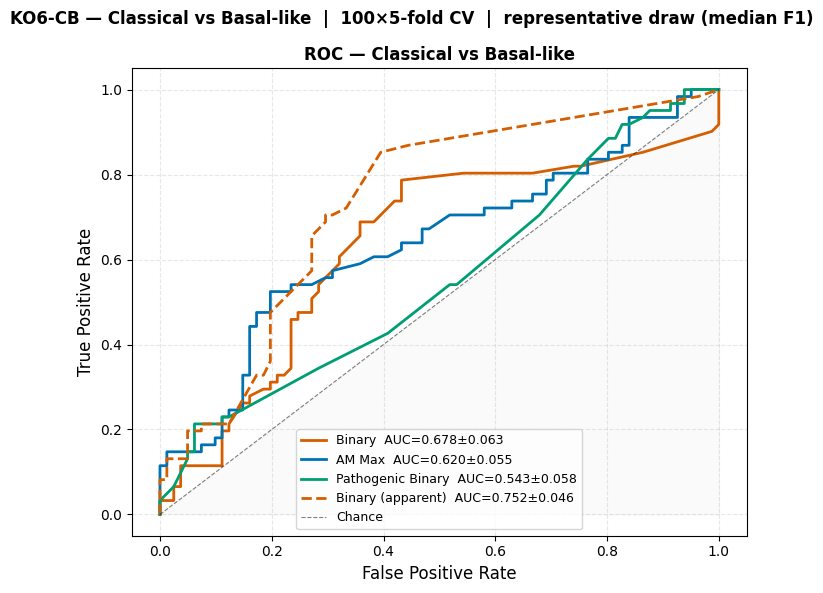

Saved -> C:\2604_BRP\Data\results\AM_CvB\KO6_CB_comparison_roc_pr.png


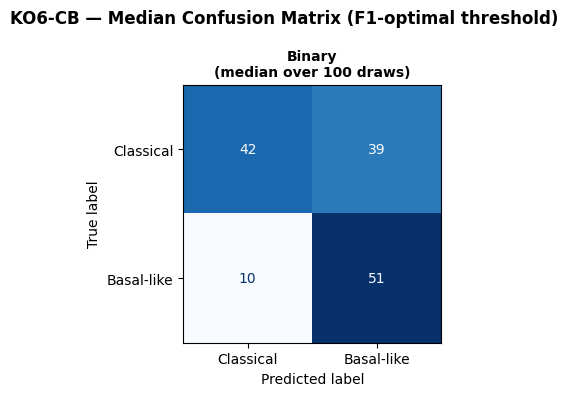

Saved -> C:\2604_BRP\Data\results\AM_CvB\KO6_CB_confusion_grid.png


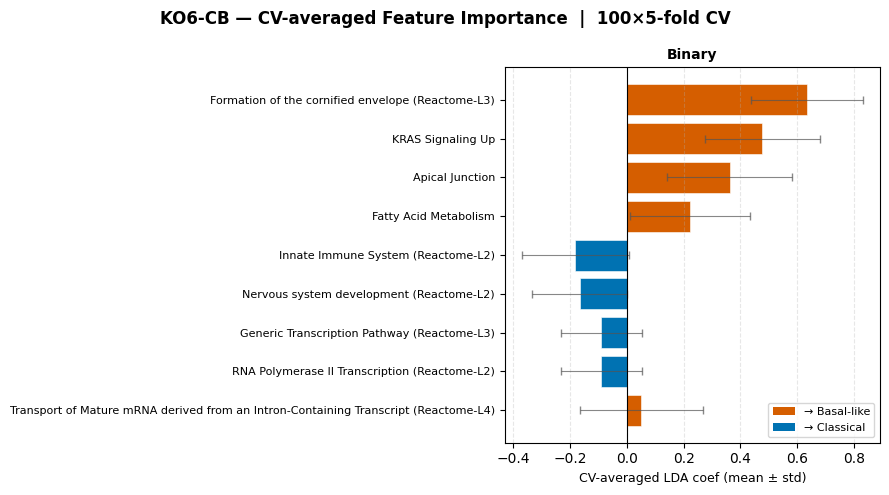

Saved -> C:\2604_BRP\Data\results\AM_CvB\KO6_CB_coef_grid.png


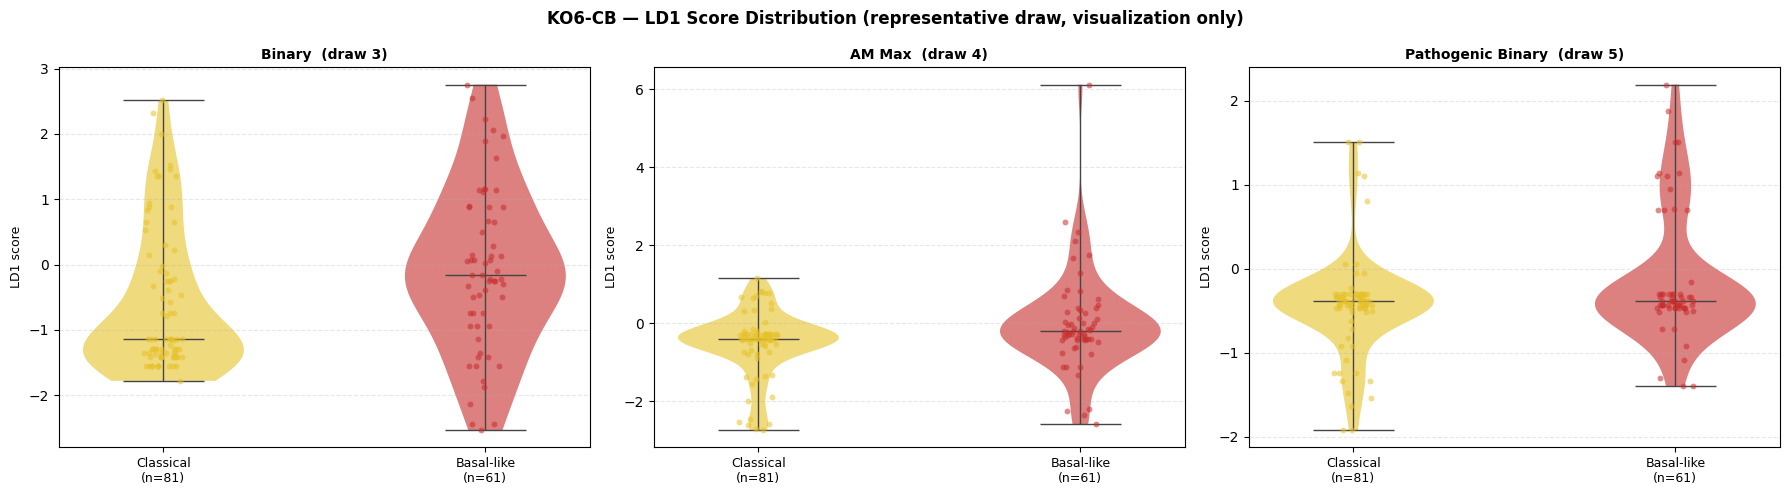

Saved -> C:\2604_BRP\Data\results\AM_CvB\KO6_CB_violin_grid.png


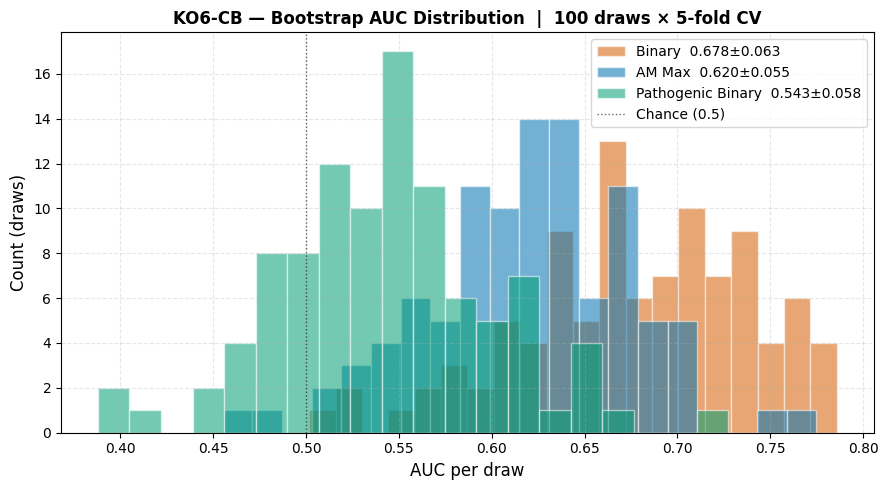

Saved -> C:\2604_BRP\Data\results\AM_CvB\KO6_CB_bootstrap_auc_dist.png


In [13]:
# ── Helpers ──────────────────────────────────────────────────────────────────
def _per_draw_metrics(oof_all, y_base):
    f1s, precs, recs, specs, aps = [], [], [], [], []
    for oof_b in oof_all:
        prec_c, rec_c, thresh_c = precision_recall_curve(y_base, oof_b)
        with np.errstate(divide='ignore', invalid='ignore'):
            f1_c = np.where((prec_c[:-1] + rec_c[:-1]) > 0,
                            2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]), 0.0)
        best_idx = int(np.argmax(f1_c)) if len(f1_c) > 0 else 0
        best_t   = float(thresh_c[best_idx]) if len(thresh_c) > 0 else 0.0
        y_pred   = (oof_b >= best_t).astype(int)
        cm       = confusion_matrix(y_base, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        f1s.append(float(f1_score(y_base, y_pred, zero_division=0)))
        precs.append(float(precision_score(y_base, y_pred, zero_division=0)))
        recs.append(float(recall_score(y_base, y_pred, zero_division=0)))
        specs.append(float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0)
        aps.append(float(average_precision_score(y_base, oof_b)))
    return (np.array(f1s), np.array(precs), np.array(recs),
            np.array(specs), np.array(aps))

def _rep_draw(oof_all, y_base):
    f1s = _per_draw_metrics(oof_all, y_base)[0]
    median_f1 = float(np.median(f1s))
    return int(np.argmin(np.abs(f1s - median_f1)))

def _median_cm(oof_all, y_base):
    cms = []
    for oof_b in oof_all:
        prec_c, rec_c, thresh_c = precision_recall_curve(y_base, oof_b)
        with np.errstate(divide='ignore', invalid='ignore'):
            f1_c = np.where((prec_c[:-1] + rec_c[:-1]) > 0,
                            2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1]), 0.0)
        best_t = float(thresh_c[int(np.argmax(f1_c))]) if len(thresh_c) > 0 else 0.0
        y_pred = (oof_b >= best_t).astype(int)
        cms.append(confusion_matrix(y_base, y_pred, labels=[0, 1]))
    return np.median(np.stack(cms, axis=0), axis=0).astype(int)

oof_all_list   = [oof_scores_bin_arr, oof_scores_am_arr, oof_scores_path_arr]
coefs_all_list = [coefs_bin_arr, coefs_am_arr, coefs_path_arr]
rep_draws      = [_rep_draw(oof_all, y_base_cvb) for oof_all in oof_all_list]

# ── Figure 1: comparison_roc_pr ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

for label, color, oof_all, rep, draw_aucs in zip(
        FEAT_LABELS, FEAT_COLORS, oof_all_list, rep_draws,
        [draw_aucs_bin_arr, draw_aucs_am_arr, draw_aucs_path_arr]):
    fpr_r, tpr_r, _ = roc_curve(y_base_cvb, oof_all[rep])
    ax.plot(fpr_r, tpr_r, color=color, lw=2,
            label=f'{label}  AUC={draw_aucs.mean():.3f}±{draw_aucs.std():.3f}')
fpr_ap, tpr_ap, _ = roc_curve(y_base_cvb, apparent_sc_bin[rep_draws[0]])
ax.plot(fpr_ap, tpr_ap, color=WONG['vermilion'], lw=2, ls='--',
        label=f'Binary (apparent)  AUC={apparent_auc_bin_arr.mean():.3f}±{apparent_auc_bin_arr.std():.3f}')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8, alpha=0.5, label='Chance')
ax.fill_between([0, 1], [0, 1], alpha=0.04, color='gray')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC — Classical vs Basal-like', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3, linestyle='--')

fig.suptitle(
    f'KO6-CB — Classical vs Basal-like  |  '
    f'{N_DRAWS}×{N_CV_SPLITS}-fold CV  |  representative draw (median F1)',
    fontsize=12, fontweight='bold',
)
plt.tight_layout()
out_roc_pr = RESULTS_DIR_CB / 'KO6_CB_comparison_roc_pr.png'
plt.savefig(out_roc_pr, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_roc_pr.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Saved -> {out_roc_pr}')

# ── Figure 2: confusion_grid ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 4))
med_cm = _median_cm(oof_all_list[0], y_base_cvb)
disp = ConfusionMatrixDisplay(med_cm, display_labels=['Classical', 'Basal-like'])
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Binary\n(median over {N_DRAWS} draws)', fontsize=10, fontweight='bold')

fig.suptitle('KO6-CB — Median Confusion Matrix (F1-optimal threshold)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
out_conf = RESULTS_DIR_CB / 'KO6_CB_confusion_grid.png'
plt.savefig(out_conf, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_conf.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Saved -> {out_conf}')

# ── Figure 3: coef_grid ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
mean_c = coefs_bin_arr.mean(axis=0)
std_c  = coefs_bin_arr.std(axis=0)
order  = np.argsort(np.abs(mean_c))
labels_pw = []
for i in order:
    pw  = KOCOFX_CB_PATHWAYS[i]
    tag = pw_level_tag(pw)
    prefix = 'HALLMARK_' if pw.startswith('HALLMARK_') else 'REACTOME_'
    labels_pw.append(f'{pw[len(prefix):]} {tag}'.strip())
vals   = mean_c[order]
errs   = std_c[order]
colors = [WONG['vermilion'] if v > 0 else WONG['blue'] for v in vals]
ax.barh(range(len(vals)), vals,
        xerr=errs,
        error_kw={'ecolor': '#555555', 'capsize': 3, 'linewidth': 0.8, 'alpha': 0.7},
        color=colors, edgecolor='white', linewidth=0.4)
ax.set_yticks(range(len(labels_pw)))
ax.set_yticklabels(labels_pw, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel(f'CV-averaged LDA coef (mean ± std)', fontsize=9)
ax.set_title('Binary', fontsize=10, fontweight='bold')
ax.legend(handles=[
    mpatches.Patch(facecolor=WONG['vermilion'], label='→ Basal-like'),
    mpatches.Patch(facecolor=WONG['blue'],      label='→ Classical'),
], fontsize=8, loc='lower right')
ax.grid(axis='x', alpha=0.3, linestyle='--')

fig.suptitle(f'KO6-CB — CV-averaged Feature Importance  |  {N_DRAWS}×{N_CV_SPLITS}-fold CV',
             fontsize=12, fontweight='bold')
plt.tight_layout()
out_coef = RESULTS_DIR_CB / 'KO6_CB_coef_grid.png'
plt.savefig(out_coef, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_coef.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Saved -> {out_coef}')
# ── Figure 4: violin_grid ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cl_mask_cvb = y_base_cvb == 0
bl_mask_cvb = y_base_cvb == 1

for ax, label, oof_all, rep in zip(axes, FEAT_LABELS, oof_all_list, rep_draws):
    oof_rep = oof_all[rep]
    data_cl = oof_rep[cl_mask_cvb]
    data_bl = oof_rep[bl_mask_cvb]

    vp = ax.violinplot([data_cl, data_bl], positions=[0, 1], showmedians=True, showextrema=True)
    for pc, c in zip(vp['bodies'], [YELLOW_WARM, RED_DEEP]):
        pc.set_facecolor(c)
        pc.set_alpha(0.6)
    for part in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
        if part in vp:
            vp[part].set_color('#444444')
            vp[part].set_linewidth(1.0)

    rng_jit = np.random.default_rng(RANDOM_SEED)
    ax.scatter(rng_jit.uniform(-0.06, 0.06, cl_mask_cvb.sum()),
               data_cl, c=YELLOW_WARM, s=18, alpha=0.55, linewidths=0, zorder=3)
    ax.scatter(1 + rng_jit.uniform(-0.06, 0.06, bl_mask_cvb.sum()),
               data_bl, c=RED_DEEP,    s=18, alpha=0.55, linewidths=0, zorder=3)

    ax.set_xticks([0, 1])
    ax.set_xticklabels([f'Classical\n(n={cl_mask_cvb.sum()})',
                         f'Basal-like\n(n={bl_mask_cvb.sum()})'], fontsize=9)
    ax.set_ylabel('LD1 score', fontsize=9)
    ax.set_title(f'{label}  (draw {rep})', fontsize=10, fontweight='bold')
    ax.grid(axis='y', alpha=0.3, linestyle='--')

fig.suptitle('KO6-CB — LD1 Score Distribution (representative draw, visualization only)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
out_violin = RESULTS_DIR_CB / 'KO6_CB_violin_grid.png'
plt.savefig(out_violin, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_violin.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Saved -> {out_violin}')

# ── Figure 5: bootstrap AUC distribution ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
for label, color, draw_aucs in zip(
        FEAT_LABELS, FEAT_COLORS,
        [draw_aucs_bin_arr, draw_aucs_am_arr, draw_aucs_path_arr]):
    ax.hist(draw_aucs, bins=20, color=color, alpha=0.55, edgecolor='white',
            label=f'{label}  {draw_aucs.mean():.3f}±{draw_aucs.std():.3f}')
ax.axvline(0.5, color='black', lw=1.0, ls=':', alpha=0.6, label='Chance (0.5)')
ax.set_xlabel('AUC per draw', fontsize=12)
ax.set_ylabel('Count (draws)', fontsize=12)
ax.set_title(
    f'KO6-CB — Bootstrap AUC Distribution  |  {N_DRAWS} draws × {N_CV_SPLITS}-fold CV',
    fontsize=12, fontweight='bold',
)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
out_auc_dist = RESULTS_DIR_CB / 'KO6_CB_bootstrap_auc_dist.png'
plt.savefig(out_auc_dist, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_auc_dist.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Saved -> {out_auc_dist}')

Saved to C:\2604_BRP\Data\results\AM_CvB


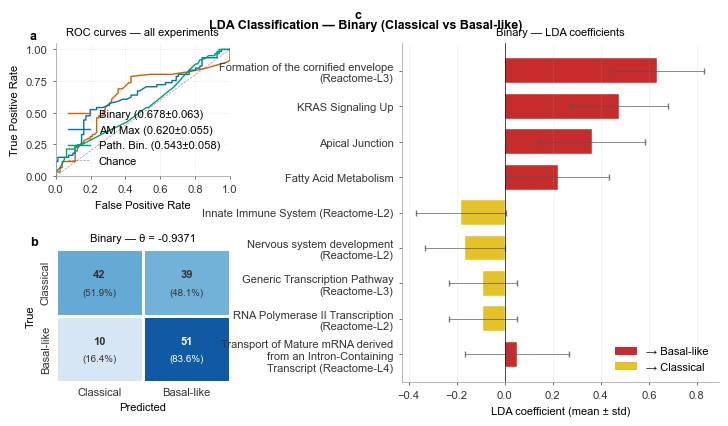

In [ ]:
# ── 11b. Nature-style 3-panel figure: PR · CM · LDA coefficients (CvB) ──────────
import matplotlib as mpl
from matplotlib import gridspec
import seaborn as sns
import textwrap

_mm = 1 / 25.4

# ── Compute ROC curves from representative draws ────────────────────────────────
_fpr_cb_bin,  _tpr_cb_bin,  _ = roc_curve(y_base_cvb, oof_all_list[0][rep_draws[0]])
_fpr_cb_am,   _tpr_cb_am,   _ = roc_curve(y_base_cvb, oof_all_list[1][rep_draws[1]])
_fpr_cb_path, _tpr_cb_path, _ = roc_curve(y_base_cvb, oof_all_list[2][rep_draws[2]])

# F1-optimal threshold for Binary (for CM title)
_prec_t, _rec_t, _thresh_t = precision_recall_curve(y_base_cvb, oof_all_list[0][rep_draws[0]])
with np.errstate(divide='ignore', invalid='ignore'):
    _f1_t = np.where((_prec_t[:-1] + _rec_t[:-1]) > 0,
                     2 * _prec_t[:-1] * _rec_t[:-1] / (_prec_t[:-1] + _rec_t[:-1]), 0.0)
_threshold_bin_cvb = float(_thresh_t[int(np.argmax(_f1_t))]) if len(_thresh_t) > 0 else 0.0

# Median CM for Binary
_cm_med_bin_cvb = _median_cm(oof_all_list[0], y_base_cvb)

# Coefficients for Binary
_mean_coef_bin_cvb = coefs_bin_arr.mean(axis=0)
_std_coef_bin_cvb  = coefs_bin_arr.std(axis=0)

with mpl.rc_context({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.linewidth': 0.5,
    'axes.edgecolor': '#999999',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
    'svg.fonttype': 'none',
}):
    _fig_cb = plt.figure(figsize=(183 * _mm, 105 * _mm))
    _gs_cb = gridspec.GridSpec(
        2, 2, figure=_fig_cb,
        height_ratios=[1, 1],
        width_ratios=[0.55, 1.0],
        hspace=0.55, wspace=0.70,
        left=0.07, right=0.99, top=0.92, bottom=0.10,
    )
    _ax_pr = _fig_cb.add_subplot(_gs_cb[0, 0])   # top-left
    _ax_cm = _fig_cb.add_subplot(_gs_cb[1, 0])   # bottom-left
    _ax_bc = _fig_cb.add_subplot(_gs_cb[:, 1])    # right, full height

    # Bold panel labels
    for _ax_cb, _lbl_cb in zip([_ax_pr, _ax_cm, _ax_bc], ['a', 'b', 'c']):
        _ax_cb.text(-0.15, 1.10, _lbl_cb, transform=_ax_cb.transAxes,
                    fontsize=9, fontweight='bold', va='top', ha='left')

    # ── a) ROC curves — all three experiments ───────────────────────────────────
    for _label_cb, _color_cb, _fpr_cb, _tpr_cb, _auc_cb, _std_cb in [
        ('Binary',     FEAT_COLORS[0], _fpr_cb_bin,  _tpr_cb_bin,
         draw_aucs_bin_arr.mean(),  draw_aucs_bin_arr.std()),
        ('AM Max',     FEAT_COLORS[1], _fpr_cb_am,   _tpr_cb_am,
         draw_aucs_am_arr.mean(),   draw_aucs_am_arr.std()),
        ('Path. Bin.', FEAT_COLORS[2], _fpr_cb_path, _tpr_cb_path,
         draw_aucs_path_arr.mean(), draw_aucs_path_arr.std()),
    ]:
        _ax_pr.plot(_fpr_cb, _tpr_cb, color=_color_cb, lw=1.0,
                    label=f'{_label_cb} ({_auc_cb:.3f}±{_std_cb:.3f})')
    _ax_pr.plot([0, 1], [0, 1], 'k--', lw=0.5, alpha=0.4, label='Chance')
    _ax_pr.set_xlim(0, 1)
    _ax_pr.set_ylim(0, 1.05)
    _ax_pr.set_xlabel('False Positive Rate')
    _ax_pr.set_ylabel('True Positive Rate')
    _ax_pr.set_title('ROC curves — all experiments')
    _ax_pr.legend(frameon=False, loc='lower right')
    _ax_pr.grid(alpha=0.3, ls='--', linewidth=0.4)
    sns.despine(ax=_ax_pr)

    # ── b) Confusion matrix \u2014 Binary (KO5 style) ───────────────────────────────
    _cm_norm_cb = _cm_med_bin_cvb.astype(float) / _cm_med_bin_cvb.sum(axis=1, keepdims=True)
    sns.heatmap(
        _cm_norm_cb, annot=False, cmap='Blues', vmin=0, vmax=1,
        xticklabels=['Classical', 'Basal-like'], yticklabels=['Classical', 'Basal-like'],
        linewidths=1.0, linecolor='white', ax=_ax_cm, cbar=False,
    )
    for _i_cb in range(2):
        for _j_cb in range(2):
            _tc_cb = 'white' if _cm_norm_cb[_i_cb, _j_cb] > 0.55 else '#333333'
            _ax_cm.text(_j_cb + 0.5, _i_cb + 0.38, f'{_cm_med_bin_cvb[_i_cb, _j_cb]}',
                        ha='center', va='center', fontweight='bold', color=_tc_cb)
            _pct_cb = _cm_norm_cb[_i_cb, _j_cb] * 100
            _ax_cm.text(_j_cb + 0.5, _i_cb + 0.65, f'({_pct_cb:.1f}%)',
                        ha='center', va='center', fontsize=7, color=_tc_cb)
    _ax_cm.set_xlabel('Predicted')
    _ax_cm.set_ylabel('True')
    _ax_cm.set_title(f'Binary \u2014 \u03b8 = {_threshold_bin_cvb:.4f}')
    _ax_cm.tick_params(axis='both', length=0)

    # ── c) LDA coefficient bar chart \u2014 Binary ──────────────────────────────────
    _order_cb = np.argsort(np.abs(_mean_coef_bin_cvb))
    _labels_cb = []
    for _i_pw in _order_cb:
        _pw = KOCOFX_CB_PATHWAYS[_i_pw]
        _tag = pw_level_tag(_pw)
        _prefix = 'HALLMARK_' if _pw.startswith('HALLMARK_') else 'REACTOME_'
        _labels_cb.append(f'{_pw[len(_prefix):]} {_tag}'.strip())
    _labels_cb = [textwrap.fill(l, 35) for l in _labels_cb]
    _vals_cb = _mean_coef_bin_cvb[_order_cb]
    _errs_cb = _std_coef_bin_cvb[_order_cb]
    _bar_colors_cb = [RED_DEEP if v > 0 else YELLOW_WARM for v in _vals_cb]
    _ax_bc.barh(range(len(_vals_cb)), _vals_cb, xerr=_errs_cb,
                error_kw={'ecolor': '#555555', 'capsize': 2, 'linewidth': 0.6, 'alpha': 0.8},
                color=_bar_colors_cb, edgecolor='white', linewidth=0.3, height=0.7)
    _ax_bc.set_yticks(range(len(_labels_cb)))
    _ax_bc.set_yticklabels(_labels_cb)
    _ax_bc.axvline(0, color='black', linewidth=0.5)
    _ax_bc.set_xlabel('LDA coefficient (mean \u00b1 std)')
    _ax_bc.set_title('Binary \u2014 LDA coefficients')
    _ax_bc.legend(handles=[
        mpatches.Patch(facecolor=RED_DEEP,    label='\u2192 Basal-like'),
        mpatches.Patch(facecolor=YELLOW_WARM, label='\u2192 Classical'),
    ], frameon=False, loc='lower right')
    _ax_bc.grid(axis='x', alpha=0.3, ls='--', linewidth=0.4)
    sns.despine(ax=_ax_bc)

    _fig_cb.suptitle(
        'LDA Classification \u2014 Binary (Classical vs Basal-like)',
        fontsize=9, fontweight='bold',
    )

    _figname_cb = 'KO6_CB_nature_panel'
    plt.savefig(RESULTS_DIR_CB / f'{_figname_cb}.pdf', dpi=300)
    plt.savefig(RESULTS_DIR_CB / f'{_figname_cb}.png', dpi=300)
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(RESULTS_DIR_CB / f'{_figname_cb}.svg')
    print('Saved to', RESULTS_DIR_CB.resolve())
    plt.show()


## 12. Results File (CvB)

In [13]:
# Collect per-draw metrics for all 3 feature types
_all_metrics = {}
for feat_label, oof_all, draw_aucs, draw_auprcs, apparent_aucs, apparent_auprcs in [
    ('Binary',            oof_scores_bin_arr,  draw_aucs_bin_arr,  draw_auprcs_bin_arr,
     apparent_auc_bin_arr, np.array([average_precision_score(y_base_cvb, s) for s in apparent_sc_bin])),
    ('AM Max',            oof_scores_am_arr,   draw_aucs_am_arr,   draw_auprcs_am_arr,
     apparent_auc_am_arr,  np.array([average_precision_score(y_base_cvb, s) for s in apparent_sc_am])),
    ('Pathogenic Binary', oof_scores_path_arr, draw_aucs_path_arr, draw_auprcs_path_arr,
     apparent_auc_path_arr,np.array([average_precision_score(y_base_cvb, s) for s in apparent_sc_path])),
]:
    f1s, precs, recs, specs, _ = _per_draw_metrics(oof_all, y_base_cvb)
    _all_metrics[feat_label] = {
        'auroc':          (draw_aucs.mean(),       draw_aucs.std()),
        'auprc':          (draw_auprcs.mean(),      draw_auprcs.std()),
        'ap_auroc':       (apparent_aucs.mean(),    apparent_aucs.std()),
        'ap_auprc':       (apparent_auprcs.mean(),  apparent_auprcs.std()),
        'f1':             (f1s.mean(),              f1s.std()),
        'precision':      (precs.mean(),            precs.std()),
        'recall':         (recs.mean(),             recs.std()),
        'specificity':    (specs.mean(),            specs.std()),
    }

lines = []
lines.append('=' * 80)
lines.append('KO6-CB -- Subagging-Ensemble LDA: Classical vs Basal-like')
lines.append('AM-derived feature comparison  |  9 KoCoFX-CB pathways')
lines.append('=' * 80)
lines.append('')
lines.append('SETUP')
lines.append(f'  Classifier    : LDA (eigen solver, Ledoit-Wolf shrinkage)')
lines.append(f'  Features      : {len(KOCOFX_CB_PATHWAYS)} KoCoFX-CB pathways')
lines.append(f'  Draws         : {N_DRAWS}  |  CV splits: {N_CV_SPLITS}-fold stratified  |  Total fits: {N_DRAWS * N_CV_SPLITS}')
lines.append(f'  Patients      : {n_cvb}  (Classical: {n_classical}, Basal-like: {n_basal})')
lines.append(f'  AM threshold  : {AM_PATH_MIN} (pathogenic binary)')
lines.append(f'  Aggregation   : mean ± std over {N_DRAWS} draws')
lines.append(f'  Seed          : {RANDOM_SEED}')
lines.append('')

METRIC_LABELS = ['AUROC (OOF)', 'AUPRC (OOF)', 'AUROC (Apparent)', 'AUPRC (Apparent)',
                 'F1', 'Precision', 'Recall', 'Specificity']
METRIC_KEYS   = ['auroc', 'auprc', 'ap_auroc', 'ap_auprc', 'f1', 'precision', 'recall', 'specificity']

for feat_label in ['Binary', 'AM Max', 'Pathogenic Binary']:
    m = _all_metrics[feat_label]
    lines.append('=' * 80)
    lines.append(f'Experiment: {feat_label}')
    lines.append('=' * 80)
    for ml, mk in zip(METRIC_LABELS, METRIC_KEYS):
        mu, sd = m[mk]
        lines.append(f'  {ml:<22}: {mu:.4f} ± {sd:.4f}')
    # CV-averaged coefficients
    coefs_a = {'Binary': coefs_bin_arr, 'AM Max': coefs_am_arr,
               'Pathogenic Binary': coefs_path_arr}[feat_label]
    mean_c = coefs_a.mean(axis=0)
    std_c  = coefs_a.std(axis=0)
    lines.append('')
    lines.append('  CV-averaged LDA coefficients (ranked by |mean coef|):')
    lines.append(f'  {"Rank":<5}  {"Pathway":<75}  {"Mean":>8}  {"Std":>7}  {"Direction":<16}')
    lines.append('  ' + '-' * 115)
    for rank, i in enumerate(np.argsort(np.abs(mean_c))[::-1], 1):
        pw    = KOCOFX_CB_PATHWAYS[i]
        tag   = pw_level_tag(pw)
        lbl   = f'{pw} {tag}'.strip()
        direc = '→ Basal-like' if mean_c[i] > 0 else '→ Classical'
        lines.append(f'  {rank:<5}  {lbl:<75}  {mean_c[i]:>+8.4f}  {std_c[i]:>7.4f}  {direc}')
    lines.append('')

# Comparison table
lines.append('=' * 80)
lines.append('COMPARISON TABLE')
lines.append('=' * 80)
header = f'  {"Metric":<24}  {"Binary":>20}  {"AM Max":>20}  {"Pathogenic Binary":>20}'
lines.append(header)
lines.append('  ' + '-' * (len(header) - 2))
for ml, mk in zip(METRIC_LABELS, METRIC_KEYS):
    row = f'  {ml:<24}'
    for feat_label in ['Binary', 'AM Max', 'Pathogenic Binary']:
        mu, sd = _all_metrics[feat_label][mk]
        row += f'  {mu:.4f} ± {sd:.4f}'
    lines.append(row)

lines.append('')
lines.append('-' * 80)
lines.append(f'  TCGA parquet: {PARQUET}')
lines.append(f'  Results dir : {RESULTS_DIR_CB}')
lines.append('-' * 80)

out_txt = RESULTS_DIR_CB / 'KO6_CB_results.txt'
out_txt.write_text('\n'.join(lines), encoding='utf-8')
print(f'Results written -> {out_txt}')
for feat_label in ['Binary', 'AM Max', 'Pathogenic Binary']:
    m = _all_metrics[feat_label]
    print(f'{feat_label:<22}: AUC={m["auroc"][0]:.3f}±{m["auroc"][1]:.3f}  '
          f'AUPRC={m["auprc"][0]:.3f}±{m["auprc"][1]:.3f}  '
          f'F1={m["f1"][0]:.3f}±{m["f1"][1]:.3f}')

Results written -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_results.txt
Binary                : AUC=0.678±0.063  AUPRC=0.613±0.063  F1=0.666±0.042
AM Max                : AUC=0.620±0.055  AUPRC=0.583±0.051  F1=0.627±0.031
Pathogenic Binary     : AUC=0.543±0.058  AUPRC=0.480±0.050  F1=0.620±0.016


## 13. Bootstrap & Fixed Folds (3-class: CvBvUnknown)

In [14]:
n_unknown_3 = (y_3class == 2).sum()

y_base_3 = np.concatenate([
    np.zeros(n_classical, dtype=np.int8),
    np.ones(n_basal, dtype=np.int8),
    np.full(n_unknown_3, 2, dtype=np.int8),
])
cvb_mask_3 = y_base_3 < 2   # True for Classical (0) and Basal-like (1)

skf_3class    = StratifiedKFold(n_splits=N_CV_SPLITS, shuffle=True, random_state=RANDOM_SEED)
splits_3class = list(skf_3class.split(np.zeros(n_3class), y_base_3))

cl_src_3  = np.where(y_3class == 0)[0]
bl_src_3  = np.where(y_3class == 1)[0]
unk_src_3 = np.where(y_3class == 2)[0]

def bootstrap_3class(rng):
    boot_cl  = rng.choice(len(cl_src_3),  size=len(cl_src_3),  replace=True)
    boot_bl  = rng.choice(len(bl_src_3),  size=len(bl_src_3),  replace=True)
    boot_unk = rng.choice(len(unk_src_3), size=len(unk_src_3), replace=True)
    return np.concatenate([cl_src_3[boot_cl], bl_src_3[boot_bl], unk_src_3[boot_unk]])

def _pad_proba(raw_p, classes, n_rows):
    """Zero-pad predict_proba to 3 columns when a CV fold was trained on < 3 classes."""
    if raw_p.shape[1] == 3:
        return raw_p
    full_p = np.zeros((n_rows, 3), dtype=np.float32)
    for k, cls in enumerate(classes):
        full_p[:, cls] = raw_p[:, k]
    return full_p

def _pad_coef(lda):
    """Zero-pad lda.coef_ to shape (3, n_features) when trained on < 3 classes."""
    if lda.coef_.shape[0] == 3:
        return lda.coef_
    full = np.zeros((3, lda.coef_.shape[1]), dtype=np.float32)
    for k, cls in enumerate(lda.classes_):
        full[cls] = lda.coef_[k]
    return full

if n_unknown_3 == 0:
    SKIP_3CLASS = True
    print('WARNING: n_unknown = 0 — all TCGA patients are labelled Classical or Basal-like.')
    print('3-class experiments (Cells 14–18) will be skipped.')
    print('Provide a dataset with Unknown-subtype patients to enable them.')
else:
    SKIP_3CLASS = False

print(f'3-class: {n_classical} Classical + {n_basal} Basal-like + {n_unknown_3} Unknown = {n_3class}')
print(f'SKIP_3CLASS = {SKIP_3CLASS}')

3-class: 81 Classical + 61 Basal-like + 25 Unknown = 167
SKIP_3CLASS = False


## 14. Experiment 4 — Binary (3-class): Bootstrap-CV + Apparent

In [15]:
CACHE_3BIN    = RESULTS_DIR_CB / 'binary_3class_cache.npz'
CACHE_3BIN_AP = RESULTS_DIR_CB / 'binary_3class_apparent.npz'

if SKIP_3CLASS:
    print('Binary 3-class experiment skipped (n_unknown = 0).')
else:
    # ── CV ────────────────────────────────────────────────────────────────────────
    if CACHE_3BIN.exists():
        _d = np.load(CACHE_3BIN, allow_pickle=False)
        if 'per_draw_renorm_aucs' in _d:
            oof_proba_3bin   = list(_d['oof_proba'])
            coefs_3bin       = list(_d['coefs'])
            draw_aucs_3bin   = list(_d['per_draw_renorm_aucs'])
            draw_auprcs_3bin = list(_d['per_draw_renorm_auprcs'])
            start_3bin       = len(draw_aucs_3bin)
            print(f'Resuming binary 3-class CV from draw {start_3bin}/{N_DRAWS}')
        else:
            print('Stale cache (old metric key) — restarting from draw 0')
            oof_proba_3bin, coefs_3bin, draw_aucs_3bin, draw_auprcs_3bin = [], [], [], []
            start_3bin = 0
    else:
        oof_proba_3bin, coefs_3bin, draw_aucs_3bin, draw_auprcs_3bin = [], [], [], []
        start_3bin = 0
        print('Starting binary 3-class CV')

    for b in tqdm(range(start_3bin, N_DRAWS), desc='Draws (binary 3-class)', initial=start_3bin, total=N_DRAWS):
        rng      = np.random.default_rng(RANDOM_SEED + b)
        boot_idx = bootstrap_3class(rng)
        X_b      = X_3class_binary[boot_idx]

        oof_proba_b = np.zeros((n_3class, 3), dtype=np.float32)
        coef_b      = []

        for train_idx, test_idx in splits_3class:
            sc  = StandardScaler().fit(X_b[train_idx])
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                lda.fit(sc.transform(X_b[train_idx]), y_base_3[train_idx])
            raw_p = lda.predict_proba(sc.transform(X_b[test_idx]))
            oof_proba_b[test_idx] = _pad_proba(raw_p, lda.classes_, len(test_idx))
            coef_b.append(_pad_coef(lda))

        oof_proba_3bin.append(oof_proba_b)
        coefs_3bin.append(np.mean(coef_b, axis=0).astype(np.float32))
        renorm = (oof_proba_b[cvb_mask_3, 1]
                  / (oof_proba_b[cvb_mask_3, 0] + oof_proba_b[cvb_mask_3, 1] + 1e-9))
        draw_aucs_3bin.append(float(roc_auc_score(y_base_3[cvb_mask_3], renorm)))
        draw_auprcs_3bin.append(float(average_precision_score(y_base_3[cvb_mask_3], renorm)))

        np.savez(CACHE_3BIN,
                 oof_proba              = np.array(oof_proba_3bin,   dtype=np.float32),
                 coefs                  = np.array(coefs_3bin,       dtype=np.float32),
                 per_draw_renorm_aucs   = np.array(draw_aucs_3bin,   dtype=np.float64),
                 per_draw_renorm_auprcs = np.array(draw_auprcs_3bin, dtype=np.float64))

    draw_aucs_3bin_arr   = np.array(draw_aucs_3bin)
    draw_auprcs_3bin_arr = np.array(draw_auprcs_3bin)
    coefs_3bin_arr       = np.array(coefs_3bin)       # (N_DRAWS, 3, 9)
    oof_proba_3bin_arr   = np.array(oof_proba_3bin)   # (N_DRAWS, n_3class, 3)
    print(f'Binary 3-class renorm CvB AUC : {draw_aucs_3bin_arr.mean():.3f} +/- {draw_aucs_3bin_arr.std():.3f}')
    print(f'Binary 3-class renorm CvB AUPRC: {draw_auprcs_3bin_arr.mean():.3f} +/- {draw_auprcs_3bin_arr.std():.3f}')

    # ── Apparent ──────────────────────────────────────────────────────────────────
    if CACHE_3BIN_AP.exists():
        _d = np.load(CACHE_3BIN_AP, allow_pickle=False)
        if 'per_draw_apparent_auprcs' in _d:
            apparent_proba_3bin  = list(_d['apparent_proba'])
            apparent_auc_3bin    = list(_d['per_draw_apparent_aucs'])
            apparent_auprc_3bin  = list(_d['per_draw_apparent_auprcs'])
            start_3bin_ap        = len(apparent_auc_3bin)
            print(f'Resuming binary 3-class apparent from draw {start_3bin_ap}/{N_DRAWS}')
        else:
            print('Stale apparent cache — restarting')
            apparent_proba_3bin, apparent_auc_3bin, apparent_auprc_3bin = [], [], []
            start_3bin_ap = 0
    else:
        apparent_proba_3bin, apparent_auc_3bin, apparent_auprc_3bin = [], [], []
        start_3bin_ap = 0
        print('Starting binary 3-class apparent')

    for b in tqdm(range(start_3bin_ap, N_DRAWS), desc='Apparent (binary 3-class)', initial=start_3bin_ap, total=N_DRAWS):
        rng      = np.random.default_rng(RANDOM_SEED + b)
        boot_idx = bootstrap_3class(rng)
        X_b      = X_3class_binary[boot_idx]

        sc  = StandardScaler().fit(X_b)
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda.fit(sc.transform(X_b), y_base_3)
        raw_ap     = lda.predict_proba(sc.transform(X_b))
        ap_proba_b = _pad_proba(raw_ap, lda.classes_, len(boot_idx))

        apparent_proba_3bin.append(ap_proba_b.astype(np.float32))
        renorm_ap = (ap_proba_b[cvb_mask_3, 1]
                     / (ap_proba_b[cvb_mask_3, 0] + ap_proba_b[cvb_mask_3, 1] + 1e-9))
        apparent_auc_3bin.append(float(roc_auc_score(y_base_3[cvb_mask_3], renorm_ap)))
        apparent_auprc_3bin.append(float(average_precision_score(y_base_3[cvb_mask_3], renorm_ap)))

        np.savez(CACHE_3BIN_AP,
                 apparent_proba         = np.array(apparent_proba_3bin,  dtype=np.float32),
                 per_draw_apparent_aucs  = np.array(apparent_auc_3bin,   dtype=np.float64),
                 per_draw_apparent_auprcs= np.array(apparent_auprc_3bin, dtype=np.float64))

    apparent_auc_3bin_arr   = np.array(apparent_auc_3bin)
    apparent_auprc_3bin_arr = np.array(apparent_auprc_3bin)
    print(f'Binary 3-class apparent renorm CvB AUC: {apparent_auc_3bin_arr.mean():.3f} +/- {apparent_auc_3bin_arr.std():.3f}')

Starting binary 3-class CV


Draws (binary 3-class):   0%|          | 0/100 [00:00<?, ?it/s]

Binary 3-class renorm CvB AUC : 0.680 +/- 0.062
Binary 3-class renorm CvB AUPRC: 0.614 +/- 0.062
Starting binary 3-class apparent


Apparent (binary 3-class):   0%|          | 0/100 [00:00<?, ?it/s]

Binary 3-class apparent renorm CvB AUC: 0.751 +/- 0.045


## 15. Experiment 5 — AM Max (3-class): Bootstrap-CV + Apparent

In [16]:
CACHE_3AM    = RESULTS_DIR_CB / 'am_3class_cache.npz'
CACHE_3AM_AP = RESULTS_DIR_CB / 'am_3class_apparent.npz'

if SKIP_3CLASS:
    print('AM Max 3-class experiment skipped (n_unknown = 0).')
else:
    # ── CV ────────────────────────────────────────────────────────────────────────
    if CACHE_3AM.exists():
        _d = np.load(CACHE_3AM, allow_pickle=False)
        if 'per_draw_renorm_aucs' in _d:
            oof_proba_3am   = list(_d['oof_proba'])
            coefs_3am       = list(_d['coefs'])
            draw_aucs_3am   = list(_d['per_draw_renorm_aucs'])
            draw_auprcs_3am = list(_d['per_draw_renorm_auprcs'])
            start_3am       = len(draw_aucs_3am)
            print(f'Resuming AM max 3-class CV from draw {start_3am}/{N_DRAWS}')
        else:
            print('Stale cache — restarting from draw 0')
            oof_proba_3am, coefs_3am, draw_aucs_3am, draw_auprcs_3am = [], [], [], []
            start_3am = 0
    else:
        oof_proba_3am, coefs_3am, draw_aucs_3am, draw_auprcs_3am = [], [], [], []
        start_3am = 0
        print('Starting AM max 3-class CV')

    for b in tqdm(range(start_3am, N_DRAWS), desc='Draws (AM max 3-class)', initial=start_3am, total=N_DRAWS):
        rng      = np.random.default_rng(RANDOM_SEED + b)
        boot_idx = bootstrap_3class(rng)
        X_b      = X_3class_am[boot_idx]

        oof_proba_b = np.zeros((n_3class, 3), dtype=np.float32)
        coef_b      = []

        for train_idx, test_idx in splits_3class:
            sc  = StandardScaler().fit(X_b[train_idx])
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                lda.fit(sc.transform(X_b[train_idx]), y_base_3[train_idx])
            raw_p = lda.predict_proba(sc.transform(X_b[test_idx]))
            oof_proba_b[test_idx] = _pad_proba(raw_p, lda.classes_, len(test_idx))
            coef_b.append(_pad_coef(lda))

        oof_proba_3am.append(oof_proba_b)
        coefs_3am.append(np.mean(coef_b, axis=0).astype(np.float32))
        renorm = (oof_proba_b[cvb_mask_3, 1]
                  / (oof_proba_b[cvb_mask_3, 0] + oof_proba_b[cvb_mask_3, 1] + 1e-9))
        draw_aucs_3am.append(float(roc_auc_score(y_base_3[cvb_mask_3], renorm)))
        draw_auprcs_3am.append(float(average_precision_score(y_base_3[cvb_mask_3], renorm)))

        np.savez(CACHE_3AM,
                 oof_proba              = np.array(oof_proba_3am,   dtype=np.float32),
                 coefs                  = np.array(coefs_3am,       dtype=np.float32),
                 per_draw_renorm_aucs   = np.array(draw_aucs_3am,   dtype=np.float64),
                 per_draw_renorm_auprcs = np.array(draw_auprcs_3am, dtype=np.float64))

    draw_aucs_3am_arr   = np.array(draw_aucs_3am)
    draw_auprcs_3am_arr = np.array(draw_auprcs_3am)
    coefs_3am_arr       = np.array(coefs_3am)
    oof_proba_3am_arr   = np.array(oof_proba_3am)
    print(f'AM Max 3-class renorm CvB AUC : {draw_aucs_3am_arr.mean():.3f} +/- {draw_aucs_3am_arr.std():.3f}')
    print(f'AM Max 3-class renorm CvB AUPRC: {draw_auprcs_3am_arr.mean():.3f} +/- {draw_auprcs_3am_arr.std():.3f}')

    # ── Apparent ──────────────────────────────────────────────────────────────────
    if CACHE_3AM_AP.exists():
        _d = np.load(CACHE_3AM_AP, allow_pickle=False)
        if 'per_draw_apparent_auprcs' in _d:
            apparent_proba_3am  = list(_d['apparent_proba'])
            apparent_auc_3am    = list(_d['per_draw_apparent_aucs'])
            apparent_auprc_3am  = list(_d['per_draw_apparent_auprcs'])
            start_3am_ap        = len(apparent_auc_3am)
            print(f'Resuming AM max 3-class apparent from draw {start_3am_ap}/{N_DRAWS}')
        else:
            print('Stale apparent cache — restarting')
            apparent_proba_3am, apparent_auc_3am, apparent_auprc_3am = [], [], []
            start_3am_ap = 0
    else:
        apparent_proba_3am, apparent_auc_3am, apparent_auprc_3am = [], [], []
        start_3am_ap = 0
        print('Starting AM max 3-class apparent')

    for b in tqdm(range(start_3am_ap, N_DRAWS), desc='Apparent (AM max 3-class)', initial=start_3am_ap, total=N_DRAWS):
        rng      = np.random.default_rng(RANDOM_SEED + b)
        boot_idx = bootstrap_3class(rng)
        X_b      = X_3class_am[boot_idx]

        sc  = StandardScaler().fit(X_b)
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda.fit(sc.transform(X_b), y_base_3)
        raw_ap     = lda.predict_proba(sc.transform(X_b))
        ap_proba_b = _pad_proba(raw_ap, lda.classes_, len(boot_idx))

        apparent_proba_3am.append(ap_proba_b.astype(np.float32))
        renorm_ap = (ap_proba_b[cvb_mask_3, 1]
                     / (ap_proba_b[cvb_mask_3, 0] + ap_proba_b[cvb_mask_3, 1] + 1e-9))
        apparent_auc_3am.append(float(roc_auc_score(y_base_3[cvb_mask_3], renorm_ap)))
        apparent_auprc_3am.append(float(average_precision_score(y_base_3[cvb_mask_3], renorm_ap)))

        np.savez(CACHE_3AM_AP,
                 apparent_proba         = np.array(apparent_proba_3am,  dtype=np.float32),
                 per_draw_apparent_aucs  = np.array(apparent_auc_3am,   dtype=np.float64),
                 per_draw_apparent_auprcs= np.array(apparent_auprc_3am, dtype=np.float64))

    apparent_auc_3am_arr   = np.array(apparent_auc_3am)
    apparent_auprc_3am_arr = np.array(apparent_auprc_3am)
    print(f'AM Max 3-class apparent renorm CvB AUC: {apparent_auc_3am_arr.mean():.3f} +/- {apparent_auc_3am_arr.std():.3f}')

Starting AM max 3-class CV


Draws (AM max 3-class):   0%|          | 0/100 [00:00<?, ?it/s]

AM Max 3-class renorm CvB AUC : 0.613 +/- 0.055
AM Max 3-class renorm CvB AUPRC: 0.564 +/- 0.054
Starting AM max 3-class apparent


Apparent (AM max 3-class):   0%|          | 0/100 [00:00<?, ?it/s]

AM Max 3-class apparent renorm CvB AUC: 0.712 +/- 0.038


## 16. Experiment 6 — Pathogenic Binary (3-class): Bootstrap-CV + Apparent

In [17]:
CACHE_3PATH    = RESULTS_DIR_CB / 'pathogenic_3class_cache.npz'
CACHE_3PATH_AP = RESULTS_DIR_CB / 'pathogenic_3class_apparent.npz'

if SKIP_3CLASS:
    print('Pathogenic Binary 3-class experiment skipped (n_unknown = 0).')
else:
    # ── CV ────────────────────────────────────────────────────────────────────────
    if CACHE_3PATH.exists():
        _d = np.load(CACHE_3PATH, allow_pickle=False)
        if 'per_draw_renorm_aucs' in _d:
            oof_proba_3path   = list(_d['oof_proba'])
            coefs_3path       = list(_d['coefs'])
            draw_aucs_3path   = list(_d['per_draw_renorm_aucs'])
            draw_auprcs_3path = list(_d['per_draw_renorm_auprcs'])
            start_3path       = len(draw_aucs_3path)
            print(f'Resuming pathogenic 3-class CV from draw {start_3path}/{N_DRAWS}')
        else:
            print('Stale cache — restarting from draw 0')
            oof_proba_3path, coefs_3path, draw_aucs_3path, draw_auprcs_3path = [], [], [], []
            start_3path = 0
    else:
        oof_proba_3path, coefs_3path, draw_aucs_3path, draw_auprcs_3path = [], [], [], []
        start_3path = 0
        print('Starting pathogenic 3-class CV')

    for b in tqdm(range(start_3path, N_DRAWS), desc='Draws (pathogenic 3-class)', initial=start_3path, total=N_DRAWS):
        rng      = np.random.default_rng(RANDOM_SEED + b)
        boot_idx = bootstrap_3class(rng)
        X_b      = X_3class_pathogenic[boot_idx]

        oof_proba_b = np.zeros((n_3class, 3), dtype=np.float32)
        coef_b      = []

        for train_idx, test_idx in splits_3class:
            sc  = StandardScaler().fit(X_b[train_idx])
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                lda.fit(sc.transform(X_b[train_idx]), y_base_3[train_idx])
            raw_p = lda.predict_proba(sc.transform(X_b[test_idx]))
            oof_proba_b[test_idx] = _pad_proba(raw_p, lda.classes_, len(test_idx))
            coef_b.append(_pad_coef(lda))

        oof_proba_3path.append(oof_proba_b)
        coefs_3path.append(np.mean(coef_b, axis=0).astype(np.float32))
        renorm = (oof_proba_b[cvb_mask_3, 1]
                  / (oof_proba_b[cvb_mask_3, 0] + oof_proba_b[cvb_mask_3, 1] + 1e-9))
        draw_aucs_3path.append(float(roc_auc_score(y_base_3[cvb_mask_3], renorm)))
        draw_auprcs_3path.append(float(average_precision_score(y_base_3[cvb_mask_3], renorm)))

        np.savez(CACHE_3PATH,
                 oof_proba              = np.array(oof_proba_3path,   dtype=np.float32),
                 coefs                  = np.array(coefs_3path,       dtype=np.float32),
                 per_draw_renorm_aucs   = np.array(draw_aucs_3path,   dtype=np.float64),
                 per_draw_renorm_auprcs = np.array(draw_auprcs_3path, dtype=np.float64))

    draw_aucs_3path_arr   = np.array(draw_aucs_3path)
    draw_auprcs_3path_arr = np.array(draw_auprcs_3path)
    coefs_3path_arr       = np.array(coefs_3path)
    oof_proba_3path_arr   = np.array(oof_proba_3path)
    print(f'Pathogenic 3-class renorm CvB AUC : {draw_aucs_3path_arr.mean():.3f} +/- {draw_aucs_3path_arr.std():.3f}')
    print(f'Pathogenic 3-class renorm CvB AUPRC: {draw_auprcs_3path_arr.mean():.3f} +/- {draw_auprcs_3path_arr.std():.3f}')

    # ── Apparent ──────────────────────────────────────────────────────────────────
    if CACHE_3PATH_AP.exists():
        _d = np.load(CACHE_3PATH_AP, allow_pickle=False)
        if 'per_draw_apparent_auprcs' in _d:
            apparent_proba_3path  = list(_d['apparent_proba'])
            apparent_auc_3path    = list(_d['per_draw_apparent_aucs'])
            apparent_auprc_3path  = list(_d['per_draw_apparent_auprcs'])
            start_3path_ap        = len(apparent_auc_3path)
            print(f'Resuming pathogenic 3-class apparent from draw {start_3path_ap}/{N_DRAWS}')
        else:
            print('Stale apparent cache — restarting')
            apparent_proba_3path, apparent_auc_3path, apparent_auprc_3path = [], [], []
            start_3path_ap = 0
    else:
        apparent_proba_3path, apparent_auc_3path, apparent_auprc_3path = [], [], []
        start_3path_ap = 0
        print('Starting pathogenic 3-class apparent')

    for b in tqdm(range(start_3path_ap, N_DRAWS), desc='Apparent (pathogenic 3-class)', initial=start_3path_ap, total=N_DRAWS):
        rng      = np.random.default_rng(RANDOM_SEED + b)
        boot_idx = bootstrap_3class(rng)
        X_b      = X_3class_pathogenic[boot_idx]

        sc  = StandardScaler().fit(X_b)
        lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda.fit(sc.transform(X_b), y_base_3)
        raw_ap     = lda.predict_proba(sc.transform(X_b))
        ap_proba_b = _pad_proba(raw_ap, lda.classes_, len(boot_idx))

        apparent_proba_3path.append(ap_proba_b.astype(np.float32))
        renorm_ap = (ap_proba_b[cvb_mask_3, 1]
                     / (ap_proba_b[cvb_mask_3, 0] + ap_proba_b[cvb_mask_3, 1] + 1e-9))
        apparent_auc_3path.append(float(roc_auc_score(y_base_3[cvb_mask_3], renorm_ap)))
        apparent_auprc_3path.append(float(average_precision_score(y_base_3[cvb_mask_3], renorm_ap)))

        np.savez(CACHE_3PATH_AP,
                 apparent_proba         = np.array(apparent_proba_3path,  dtype=np.float32),
                 per_draw_apparent_aucs  = np.array(apparent_auc_3path,   dtype=np.float64),
                 per_draw_apparent_auprcs= np.array(apparent_auprc_3path, dtype=np.float64))

    apparent_auc_3path_arr   = np.array(apparent_auc_3path)
    apparent_auprc_3path_arr = np.array(apparent_auprc_3path)
    print(f'Pathogenic 3-class apparent renorm CvB AUC: {apparent_auc_3path_arr.mean():.3f} +/- {apparent_auc_3path_arr.std():.3f}')

Starting pathogenic 3-class CV


Draws (pathogenic 3-class):   0%|          | 0/100 [00:00<?, ?it/s]

Pathogenic 3-class renorm CvB AUC : 0.542 +/- 0.057
Pathogenic 3-class renorm CvB AUPRC: 0.475 +/- 0.050
Starting pathogenic 3-class apparent


Apparent (pathogenic 3-class):   0%|          | 0/100 [00:00<?, ?it/s]

Pathogenic 3-class apparent renorm CvB AUC: 0.642 +/- 0.038


## 17. Comparison (3-class: CvBvUnknown) — Figures

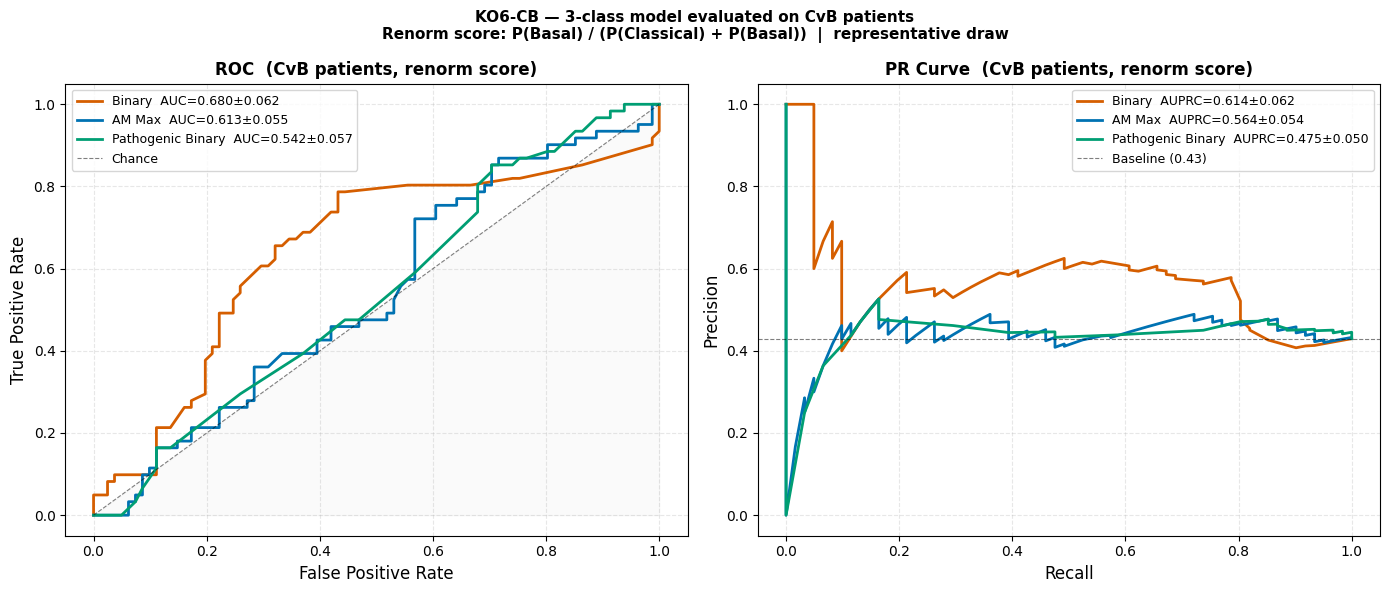

Saved -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_roc_pr.png


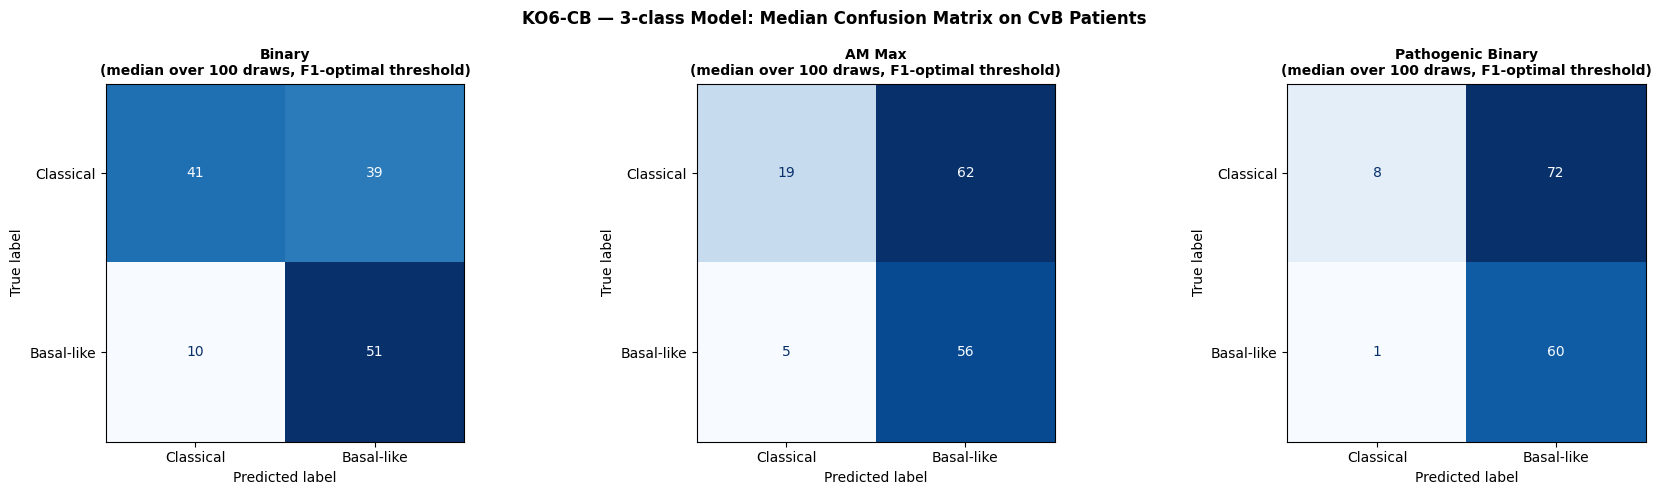

Saved -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_confusion_grid.png


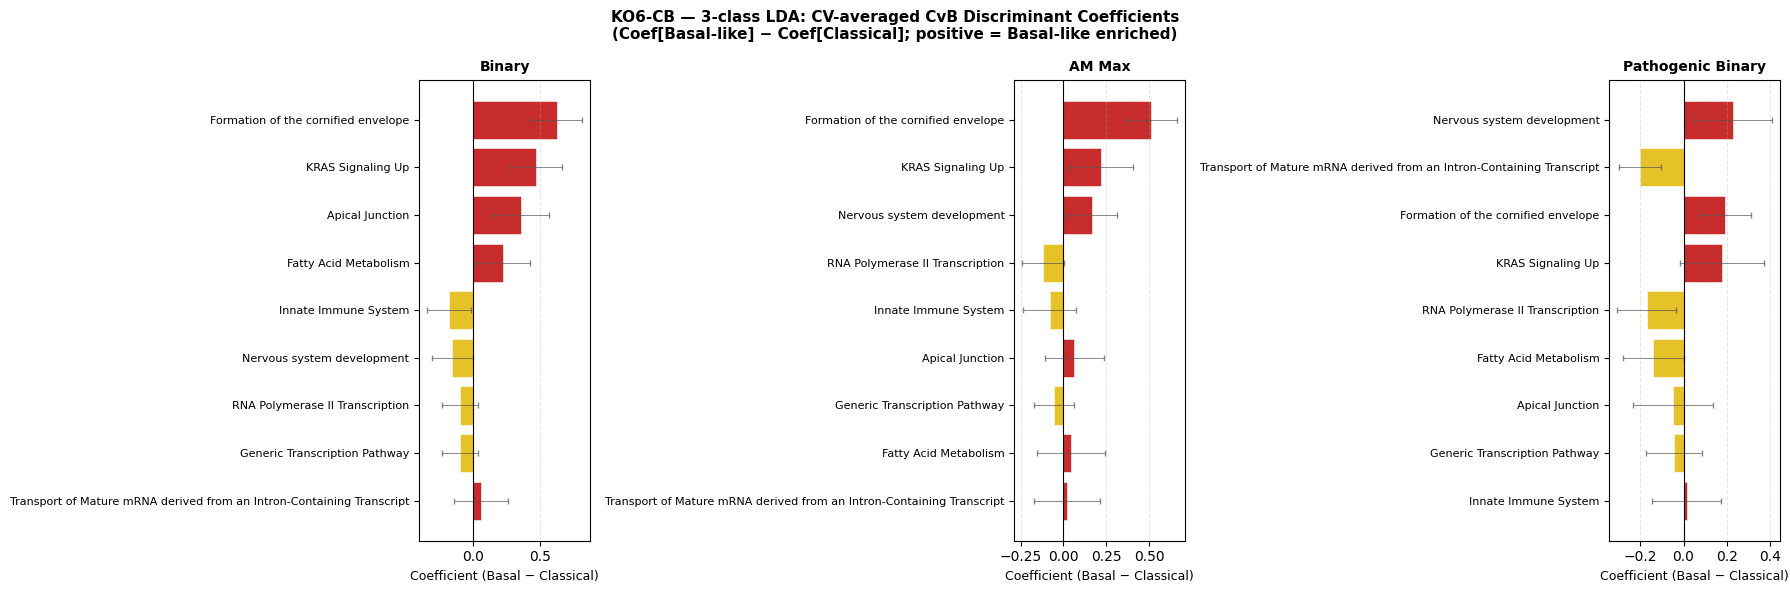

Saved -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_coef_grid.png


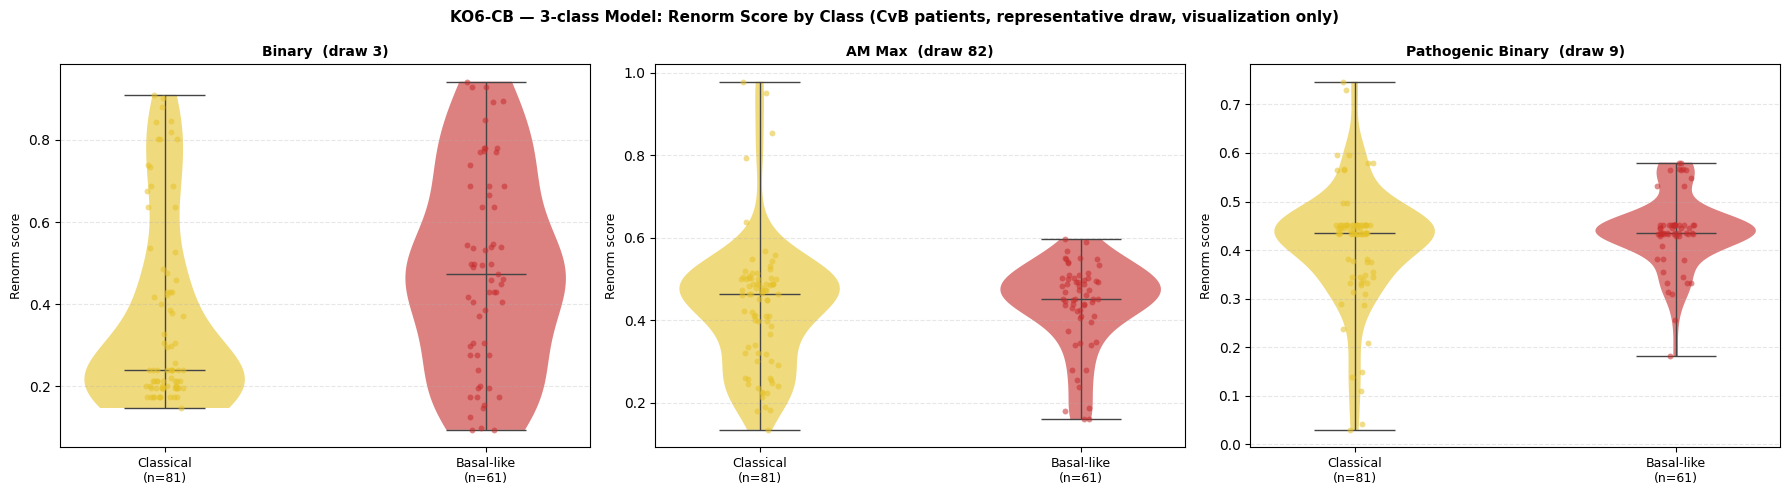

Saved -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_violin_grid.png


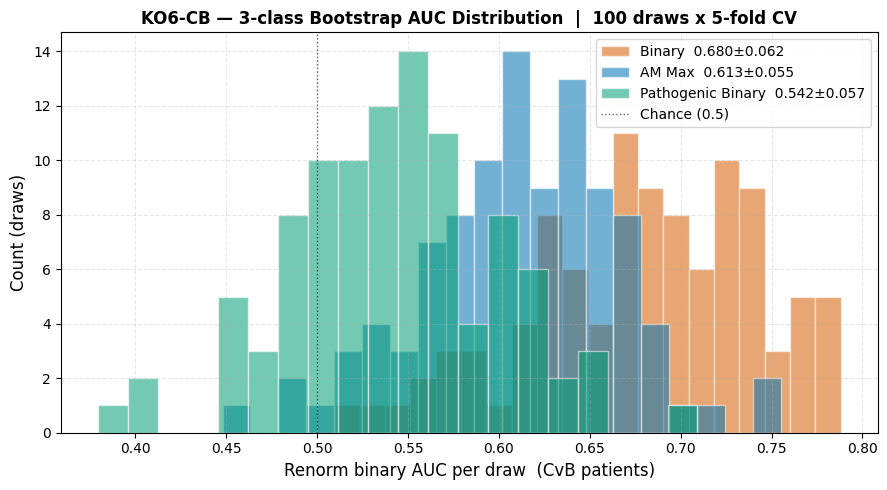

Saved -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_bootstrap_auc_dist.png


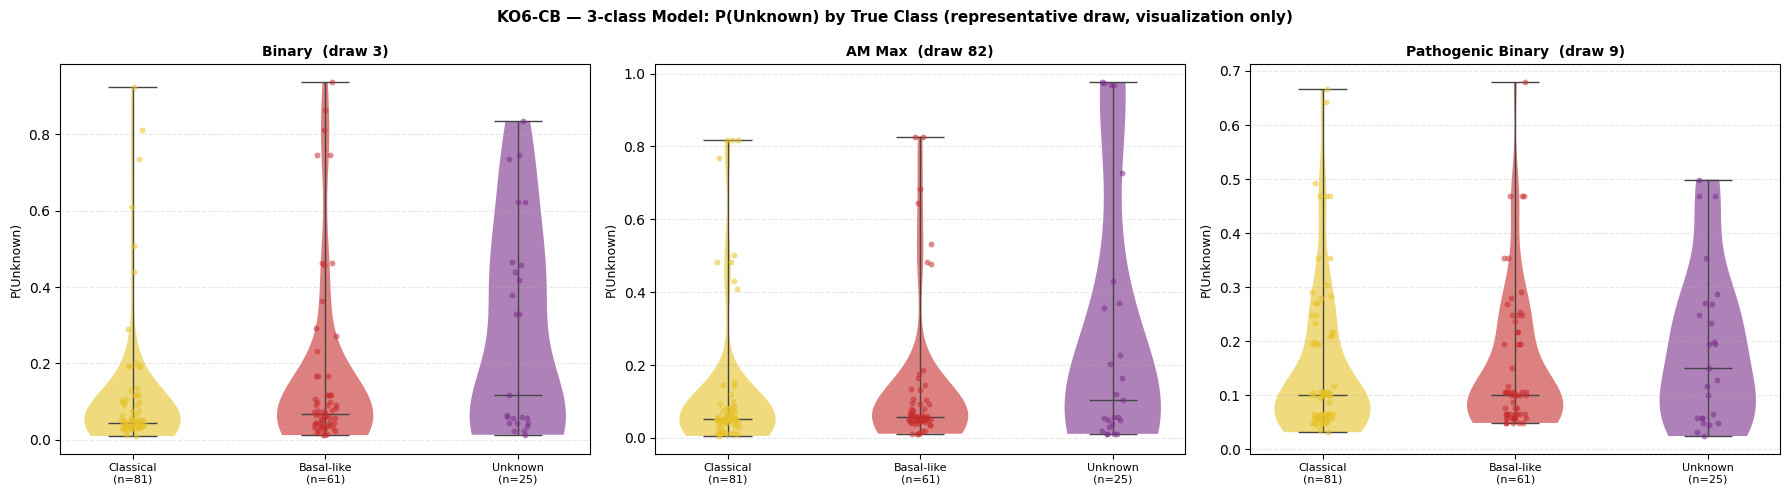

Saved -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_unknown_proba.png


In [18]:
if SKIP_3CLASS:
    print('3-class comparison figures skipped (n_unknown = 0).')
else:
    # ── Derived arrays ────────────────────────────────────────────────────────────
    def renorm_scores(proba_all):
        p = proba_all[:, cvb_mask_3, :]          # (N_DRAWS, n_cvb, 3)
        return p[:, :, 1] / (p[:, :, 0] + p[:, :, 1] + 1e-9)   # (N_DRAWS, n_cvb)

    renorm_3bin  = renorm_scores(oof_proba_3bin_arr)
    renorm_3am   = renorm_scores(oof_proba_3am_arr)
    renorm_3path = renorm_scores(oof_proba_3path_arr)

    cvb_coefs_3bin  = coefs_3bin_arr[:, 1, :]  - coefs_3bin_arr[:, 0, :]   # (N_DRAWS, 9)
    cvb_coefs_3am   = coefs_3am_arr[:, 1, :]   - coefs_3am_arr[:, 0, :]
    cvb_coefs_3path = coefs_3path_arr[:, 1, :] - coefs_3path_arr[:, 0, :]

    y_cvb_for_3    = y_base_3[cvb_mask_3]   # binary 0/1 labels for CvB patients
    renorm_all     = [renorm_3bin,  renorm_3am,  renorm_3path]
    cvb_coefs_all  = [cvb_coefs_3bin, cvb_coefs_3am, cvb_coefs_3path]
    rep_draws_3    = [_rep_draw(rn, y_cvb_for_3) for rn in renorm_all]
    draw_aucs_list_3   = [draw_aucs_3bin_arr,   draw_aucs_3am_arr,   draw_aucs_3path_arr]
    draw_auprcs_list_3 = [draw_auprcs_3bin_arr, draw_auprcs_3am_arr, draw_auprcs_3path_arr]

    # ── Figure 1: ROC + PR on CvB patients (renorm score) ────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    ax = axes[0]
    for label, color, rn, rep, draw_aucs in zip(
            FEAT_LABELS, FEAT_COLORS, renorm_all, rep_draws_3, draw_aucs_list_3):
        fpr_r, tpr_r, _ = roc_curve(y_cvb_for_3, rn[rep])
        ax.plot(fpr_r, tpr_r, color=color, lw=2,
                label=f'{label}  AUC={draw_aucs.mean():.3f}\u00b1{draw_aucs.std():.3f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8, alpha=0.5, label='Chance')
    ax.fill_between([0, 1], [0, 1], alpha=0.04, color='gray')
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title('ROC  (CvB patients, renorm score)', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, linestyle='--')

    ax = axes[1]
    for label, color, rn, rep, draw_auprcs in zip(
            FEAT_LABELS, FEAT_COLORS, renorm_all, rep_draws_3, draw_auprcs_list_3):
        prec_r, rec_r, _ = precision_recall_curve(y_cvb_for_3, rn[rep])
        ax.plot(rec_r, prec_r, color=color, lw=2,
                label=f'{label}  AUPRC={draw_auprcs.mean():.3f}\u00b1{draw_auprcs.std():.3f}')
    baseline = float(y_cvb_for_3.mean())
    ax.axhline(baseline, color='k', ls='--', lw=0.8, alpha=0.5,
               label=f'Baseline ({baseline:.2f})')
    ax.set_xlabel('Recall', fontsize=12)
    ax.set_ylabel('Precision', fontsize=12)
    ax.set_title('PR Curve  (CvB patients, renorm score)', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, linestyle='--')

    fig.suptitle(
        'KO6-CB \u2014 3-class model evaluated on CvB patients\n'
        'Renorm score: P(Basal) / (P(Classical) + P(Basal))  |  representative draw',
        fontsize=11, fontweight='bold',
    )
    plt.tight_layout()
    out = RESULTS_DIR_CB / 'KO6_CB_3class_roc_pr.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out.with_suffix('.svg'), bbox_inches='tight')
    plt.show()
    print(f'Saved -> {out}')

    # ── Figure 2: Confusion matrix grid (CvB patients, binary) ───────────────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, label, rn in zip(axes, FEAT_LABELS, renorm_all):
        med_cm = _median_cm(rn, y_cvb_for_3)
        disp = ConfusionMatrixDisplay(med_cm, display_labels=['Classical', 'Basal-like'])
        disp.plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{label}\n(median over {N_DRAWS} draws, F1-optimal threshold)',
                     fontsize=10, fontweight='bold')
    fig.suptitle('KO6-CB \u2014 3-class Model: Median Confusion Matrix on CvB Patients',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    out = RESULTS_DIR_CB / 'KO6_CB_3class_confusion_grid.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out.with_suffix('.svg'), bbox_inches='tight')
    plt.show()
    print(f'Saved -> {out}')

    # ── Figure 3: CvB discriminant coef grid (Basal - Classical direction) ────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, label, cvb_coefs in zip(axes, FEAT_LABELS, cvb_coefs_all):
        mean_c = cvb_coefs.mean(axis=0)
        std_c  = cvb_coefs.std(axis=0)
        order  = np.argsort(np.abs(mean_c))
        pw_labels = []
        for i in order:
            pw = KOCOFX_CB_PATHWAYS[i]
            prefix = 'HALLMARK_' if pw.startswith('HALLMARK_') else 'REACTOME_'
            pw_labels.append(pw[len(prefix):])
        vals   = mean_c[order]
        errs   = std_c[order]
        colors = [RED_DEEP if v > 0 else YELLOW_WARM for v in vals]
        ax.barh(range(len(vals)), vals,
                xerr=errs,
                error_kw={'ecolor': '#555555', 'capsize': 2, 'linewidth': 0.7, 'alpha': 0.7},
                color=colors, edgecolor='white', linewidth=0.4)
        ax.set_yticks(range(len(pw_labels)))
        ax.set_yticklabels(pw_labels, fontsize=8)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_title(f'{label}', fontsize=10, fontweight='bold')
        ax.set_xlabel('Coefficient (Basal \u2212 Classical)', fontsize=9)
        ax.grid(axis='x', alpha=0.3, linestyle='--')
    fig.suptitle(
        'KO6-CB \u2014 3-class LDA: CV-averaged CvB Discriminant Coefficients\n'
        '(Coef[Basal-like] \u2212 Coef[Classical]; positive = Basal-like enriched)',
        fontsize=11, fontweight='bold')
    plt.tight_layout()
    out = RESULTS_DIR_CB / 'KO6_CB_3class_coef_grid.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out.with_suffix('.svg'), bbox_inches='tight')
    plt.show()
    print(f'Saved -> {out}')

    # ── Figure 4: Violin of renorm score by class ─────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    _cvb_colors = [YELLOW_WARM, RED_DEEP]
    for ax, label, rn, rep in zip(axes, FEAT_LABELS, renorm_all, rep_draws_3):
        scores_rep = rn[rep]
        data = [scores_rep[y_cvb_for_3 == c] for c in [0, 1]]
        vp = ax.violinplot(data, positions=[0, 1], showmedians=True, showextrema=True)
        for pc, c in zip(vp['bodies'], _cvb_colors):
            pc.set_facecolor(c)
            pc.set_alpha(0.6)
        for part in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
            if part in vp:
                vp[part].set_color('#444444')
                vp[part].set_linewidth(1.0)
        rng_jit = np.random.default_rng(RANDOM_SEED)
        for pos, cls_idx, col in zip([0, 1], [0, 1], _cvb_colors):
            mask = y_cvb_for_3 == cls_idx
            jitter = rng_jit.uniform(-0.06, 0.06, mask.sum())
            ax.scatter(pos + jitter, scores_rep[mask], c=col, s=18, alpha=0.55,
                       linewidths=0, zorder=3)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([f'Classical\n(n={int((y_cvb_for_3==0).sum())})',
                             f'Basal-like\n(n={int((y_cvb_for_3==1).sum())})'], fontsize=9)
        ax.set_ylabel('Renorm score', fontsize=9)
        ax.set_title(f'{label}  (draw {rep})', fontsize=10, fontweight='bold')
        ax.grid(axis='y', alpha=0.3, linestyle='--')
    fig.suptitle(
        'KO6-CB \u2014 3-class Model: Renorm Score by Class'
        ' (CvB patients, representative draw, visualization only)',
        fontsize=11, fontweight='bold')
    plt.tight_layout()
    out = RESULTS_DIR_CB / 'KO6_CB_3class_violin_grid.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out.with_suffix('.svg'), bbox_inches='tight')
    plt.show()
    print(f'Saved -> {out}')

    # ── Figure 5: Bootstrap AUC distribution (renorm binary AUC) ─────────────────
    fig, ax = plt.subplots(figsize=(9, 5))
    for label, color, draw_aucs in zip(FEAT_LABELS, FEAT_COLORS, draw_aucs_list_3):
        ax.hist(draw_aucs, bins=20, color=color, alpha=0.55, edgecolor='white',
                label=f'{label}  {draw_aucs.mean():.3f}\u00b1{draw_aucs.std():.3f}')
    ax.axvline(0.5, color='black', lw=1.0, ls=':', alpha=0.6, label='Chance (0.5)')
    ax.set_xlabel('Renorm binary AUC per draw  (CvB patients)', fontsize=12)
    ax.set_ylabel('Count (draws)', fontsize=12)
    ax.set_title(
        f'KO6-CB \u2014 3-class Bootstrap AUC Distribution  |  {N_DRAWS} draws x {N_CV_SPLITS}-fold CV',
        fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3, linestyle='--')
    plt.tight_layout()
    out = RESULTS_DIR_CB / 'KO6_CB_3class_bootstrap_auc_dist.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out.with_suffix('.svg'), bbox_inches='tight')
    plt.show()
    print(f'Saved -> {out}')

    # ── Figure 6: P(Unknown) by true class (supplementary) ───────────────────────
    _cls_names_3  = ['Classical', 'Basal-like', 'Unknown']
    _cls_colors_3 = [YELLOW_WARM, RED_DEEP, PURPLE]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, label, proba_all, rep in zip(
            axes, FEAT_LABELS,
            [oof_proba_3bin_arr, oof_proba_3am_arr, oof_proba_3path_arr],
            rep_draws_3):
        proba_rep = proba_all[rep]
        data = [proba_rep[y_base_3 == c, 2] for c in range(3)]
        vp = ax.violinplot(data, positions=[0, 1, 2], showmedians=True, showextrema=True)
        for pc, col in zip(vp['bodies'], _cls_colors_3):
            pc.set_facecolor(col)
            pc.set_alpha(0.6)
        for part in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
            if part in vp:
                vp[part].set_color('#444444')
                vp[part].set_linewidth(1.0)
        rng_jit = np.random.default_rng(RANDOM_SEED)
        for pos, cls_idx, col in zip([0, 1, 2], [0, 1, 2], _cls_colors_3):
            mask = y_base_3 == cls_idx
            if mask.sum() > 0:
                jitter = rng_jit.uniform(-0.06, 0.06, mask.sum())
                ax.scatter(pos + jitter, proba_rep[mask, 2], c=col, s=18, alpha=0.55,
                           linewidths=0, zorder=3)
        ax.set_xticks([0, 1, 2])
        ax.set_xticklabels([f'{cn}\n(n={int((y_base_3==c).sum())})'
                             for c, cn in enumerate(_cls_names_3)], fontsize=8)
        ax.set_ylabel('P(Unknown)', fontsize=9)
        ax.set_title(f'{label}  (draw {rep})', fontsize=10, fontweight='bold')
        ax.grid(axis='y', alpha=0.3, linestyle='--')
    fig.suptitle(
        'KO6-CB \u2014 3-class Model: P(Unknown) by True Class'
        ' (representative draw, visualization only)',
        fontsize=11, fontweight='bold')
    plt.tight_layout()
    out = RESULTS_DIR_CB / 'KO6_CB_3class_unknown_proba.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out.with_suffix('.svg'), bbox_inches='tight')
    plt.show()
    print(f'Saved -> {out}')


## 18. Results File (3-class: CvBvUnknown)

In [19]:
if SKIP_3CLASS:
    print('3-class results skipped (n_unknown = 0).')
else:
    _all_metrics_3 = {}
    for feat_label, rn, draw_aucs, draw_auprcs, apparent_aucs, apparent_auprcs in [
        ('Binary',            renorm_3bin,  draw_aucs_3bin_arr,  draw_auprcs_3bin_arr,
         apparent_auc_3bin_arr,  apparent_auprc_3bin_arr),
        ('AM Max',            renorm_3am,   draw_aucs_3am_arr,   draw_auprcs_3am_arr,
         apparent_auc_3am_arr,   apparent_auprc_3am_arr),
        ('Pathogenic Binary', renorm_3path, draw_aucs_3path_arr, draw_auprcs_3path_arr,
         apparent_auc_3path_arr, apparent_auprc_3path_arr),
    ]:
        f1s, precs, recs, specs, _ = _per_draw_metrics(rn, y_cvb_for_3)
        _all_metrics_3[feat_label] = {
            'auroc':       (draw_aucs.mean(),       draw_aucs.std()),
            'auprc':       (draw_auprcs.mean(),     draw_auprcs.std()),
            'ap_auroc':    (apparent_aucs.mean(),   apparent_aucs.std()),
            'ap_auprc':    (apparent_auprcs.mean(), apparent_auprcs.std()),
            'f1':          (f1s.mean(),             f1s.std()),
            'precision':   (precs.mean(),           precs.std()),
            'recall':      (recs.mean(),            recs.std()),
            'specificity': (specs.mean(),           specs.std()),
        }

    lines3 = []
    lines3.append('=' * 80)
    lines3.append('KO6-CB -- Subagging-Ensemble LDA: Classical vs Basal-like vs Unknown (3-class)')
    lines3.append('AM-derived feature comparison  |  9 KoCoFX-CB pathways')
    lines3.append('Evaluation: renormalized P(Basal|CvB) score on CvB patients only')
    lines3.append('  Score = P(Basal) / (P(Classical) + P(Basal))  -- directly comparable to CvB binary AUC')
    lines3.append('=' * 80)
    lines3.append('')
    lines3.append('SETUP')
    lines3.append(f'  Classifier    : LDA (eigen solver, Ledoit-Wolf shrinkage)')
    lines3.append(f'  Features      : {len(KOCOFX_CB_PATHWAYS)} KoCoFX-CB pathways')
    lines3.append(f'  Draws         : {N_DRAWS}  |  CV splits: {N_CV_SPLITS}-fold stratified  |  Total fits: {N_DRAWS * N_CV_SPLITS}')
    lines3.append(f'  Training set  : {n_3class}  (Classical: {n_classical}, Basal-like: {n_basal}, Unknown: {n_unknown_3})')
    lines3.append(f'  Eval set      : {int(cvb_mask_3.sum())} CvB patients (Classical + Basal-like)')
    lines3.append(f'  AM threshold  : {AM_PATH_MIN}')
    lines3.append(f'  Aggregation   : mean +/- std over {N_DRAWS} draws')
    lines3.append(f'  Seed          : {RANDOM_SEED}')
    lines3.append('')

    METRIC_LABELS_3 = ['AUROC (OOF, renorm)',    'AUPRC (OOF, renorm)',
                        'AUROC (Apparent)',        'AUPRC (Apparent)',
                        'F1',                      'Precision',
                        'Recall',                  'Specificity']
    METRIC_KEYS_3   = ['auroc', 'auprc', 'ap_auroc', 'ap_auprc',
                        'f1', 'precision', 'recall', 'specificity']

    for feat_label in ['Binary', 'AM Max', 'Pathogenic Binary']:
        m = _all_metrics_3[feat_label]
        lines3.append('=' * 80)
        lines3.append(f'Experiment: {feat_label}')
        lines3.append('=' * 80)
        for ml, mk in zip(METRIC_LABELS_3, METRIC_KEYS_3):
            mu, sd = m[mk]
            lines3.append(f'  {ml:<28}: {mu:.4f} +/- {sd:.4f}')
        coefs_a = {'Binary': cvb_coefs_3bin, 'AM Max': cvb_coefs_3am,
                   'Pathogenic Binary': cvb_coefs_3path}[feat_label]
        mean_c = coefs_a.mean(axis=0)
        std_c  = coefs_a.std(axis=0)
        order  = np.argsort(np.abs(mean_c))[::-1]
        lines3.append('  CvB discriminant direction (Basal - Classical, desc |coef|):')
        for i in order:
            pw = KOCOFX_CB_PATHWAYS[i]
            prefix = 'HALLMARK_' if pw.startswith('HALLMARK_') else 'REACTOME_'
            lines3.append(f'    {pw[len(prefix):]:<45}: {mean_c[i]:+.4f} +/- {std_c[i]:.4f}')
        lines3.append('')

    lines3.append('=' * 80)
    lines3.append('COMPARISON TABLE')
    lines3.append('=' * 80)
    col_hdr = f'  {"Metric":<28}  {"Binary":>22}  {"AM Max":>22}  {"Pathogenic Binary":>22}'
    lines3.append(col_hdr)
    lines3.append('  ' + '-' * 99)
    for ml, mk in zip(METRIC_LABELS_3, METRIC_KEYS_3):
        row = f'  {ml:<28}'
        for feat_label in ['Binary', 'AM Max', 'Pathogenic Binary']:
            mu, sd = _all_metrics_3[feat_label][mk]
            row += f'  {mu:.4f} +/- {sd:.4f}  '
        lines3.append(row)

    lines3.append('')
    out_txt3 = RESULTS_DIR_CB / 'KO6_CB_3class_results.txt'
    out_txt3.write_text('\n'.join(lines3), encoding='utf-8')
    print(f'Results written -> {out_txt3}')
    for feat_label in ['Binary', 'AM Max', 'Pathogenic Binary']:
        m = _all_metrics_3[feat_label]
        print(f'{feat_label:<22}: renorm AUC={m["auroc"][0]:.3f}+/-{m["auroc"][1]:.3f}  '
              f'F1={m["f1"][0]:.3f}+/-{m["f1"][1]:.3f}')


Results written -> C:\Users\daane\Desktop\DATA\results\AM_CvB\KO6_CB_3class_results.txt
Binary                : renorm AUC=0.680+/-0.062  F1=0.667+/-0.042
AM Max                : renorm AUC=0.613+/-0.055  F1=0.626+/-0.028
Pathogenic Binary     : renorm AUC=0.542+/-0.057  F1=0.620+/-0.016
